# **PLC1**

##**Normal Data**

###Load and parse




In [ ]:
import pandas as pd

normal_path = "/content/normal_snapshots_PLC1.xlsx"
normal_raw = pd.read_excel(normal_path, header=None)

column_names = [
    "time",
    "current_loop",
    "loop_latency",
    "logic_execution_time",
    "tank_input_valve_status",
    "tank_input_valve_mode",
    "tank_level_value",
    "tank_level_min",
    "tank_level_max",
    "tank_output_valve_status",
    "tank_output_valve_mode",
    "tank_output_flow_value",
]

normal_records = (
    normal_raw.iloc[1:, 0]
    .dropna()
    .astype(str)
    .apply(lambda row: [value.strip() for value in row.split(",")[:12]])
    .tolist()
)

data = pd.DataFrame(normal_records, columns=column_names)
data["time"] = pd.to_datetime(data["time"], errors="coerce")

for column in column_names[1:]:
    data[column] = pd.to_numeric(data[column], errors="coerce")

data = data.sort_values("time").reset_index(drop=True)

print(f"Normal rows: {data.shape[0]} | Normal columns: {data.shape[1]}")
display(data.head())

Normal rows: 81621 | Normal columns: 12


,time,current_loop,loop_latency,logic_execution_time,tank_input_valve_status,tank_input_valve_mode,tank_level_value,tank_level_min,tank_level_max,tank_output_valve_status,tank_output_valve_mode,tank_output_flow_value
0,2025-01-09 22:43:07.335284,1736433786800,14,521,1.0,3.0,5.880000,3.0,7.0,1.0,3.0,0.0000
1,2025-01-09 22:43:07.336299,1736433787400,335,1,1.0,3.0,5.880000,3.0,7.0,1.0,3.0,0.0000
2,2025-01-09 22:43:07.613618,1736433787600,10,3,1.0,3.0,5.886667,3.0,7.0,1.0,3.0,0.0001
3,2025-01-09 22:43:07.822814,1736433787800,3,19,1.0,3.0,5.896667,3.0,7.0,1.0,3.0,0.0001
4,2025-01-09 22:43:08.009138,1736433788000,2,6,1.0,3.0,5.900000,3.0,7.0,1.0,3.0,0.0001


###Validate normal data

In [ ]:
print("Missing values:")
display(data.isna().sum())

print("Invalid timestamps:", data["time"].isna().sum())
print("Duplicate timestamps:", data["time"].duplicated().sum())
print("Time is sorted:", data["time"].is_monotonic_increasing)

normal_intervals = data["time"].diff().dt.total_seconds()
print("Time intervals in seconds:")
display(normal_intervals.describe(percentiles=[0.5, 0.95, 0.99]))

Missing values:


,0
time,0
current_loop,0
loop_latency,0
logic_execution_time,0
tank_input_valve_status,0
tank_input_valve_mode,0
tank_level_value,0
tank_level_min,0
tank_level_max,0
tank_output_valve_status,0


Invalid timestamps: 0
Duplicate timestamps: 0
Time is sorted: True
Time intervals in seconds:


,time
count,81620.000000
mean,0.200060
std,0.015628
min,0.000903
50%,0.199952
95%,0.222190
99%,0.227481
max,1.542729


##**Fault Data**

###Load and parse

In [ ]:
fault_path = "/content/faults_snapshots_PLC1.xlsx"
fault_raw = pd.read_excel(fault_path, header=None)

fault_records = (
    fault_raw.iloc[1:, 0]
    .dropna()
    .astype(str)
    .apply(lambda row: [value.strip() for value in row.split(",")[:12]])
    .tolist()
)

fault_data = pd.DataFrame(fault_records, columns=column_names)
fault_data["time"] = pd.to_datetime(fault_data["time"], errors="coerce")

for column in column_names[1:]:
    fault_data[column] = pd.to_numeric(fault_data[column], errors="coerce")

fault_data = fault_data.sort_values("time").reset_index(drop=True)

print(f"Fault rows: {fault_data.shape[0]} | Fault columns: {fault_data.shape[1]}")
display(fault_data.head())

Fault rows: 14620 | Fault columns: 12


,time,current_loop,loop_latency,logic_execution_time,tank_input_valve_status,tank_input_valve_mode,tank_level_value,tank_level_min,tank_level_max,tank_output_valve_status,tank_output_valve_mode,tank_output_flow_value
0,2025-01-10 03:22:34.402877,1736450554400,0,1,1.0,3.0,5.820000,3.0,7.0,0.0,3.0,0.0
1,2025-01-10 03:22:34.616614,1736450554600,3,13,1.0,3.0,5.793961,3.0,7.0,0.0,3.0,0.0
2,2025-01-10 03:22:37.146086,1736450554800,2,2343,1.0,3.0,5.960628,3.0,7.0,0.0,3.0,0.0
3,2025-01-10 03:22:37.153484,1736450557200,2147,6,0.0,3.0,5.960628,3.0,7.0,0.0,3.0,0.0
4,2025-01-10 03:22:37.403829,1736450557400,1,1,0.0,3.0,5.960628,3.0,7.0,0.0,3.0,0.0


###Validate fault data

In [ ]:
print("Missing values:")
display(fault_data.isna().sum())

print("Invalid timestamps:", fault_data["time"].isna().sum())
print("Duplicate timestamps:", fault_data["time"].duplicated().sum())
print("Time is sorted:", fault_data["time"].is_monotonic_increasing)

fault_intervals = fault_data["time"].diff().dt.total_seconds()
print("Time intervals in seconds:")
display(fault_intervals.describe(percentiles=[0.5, 0.95, 0.99]))

Missing values:


,0
time,0
current_loop,0
loop_latency,0
logic_execution_time,0
tank_input_valve_status,0
tank_input_valve_mode,0
tank_level_value,0
tank_level_min,0
tank_level_max,0
tank_output_valve_status,0


Invalid timestamps: 0
Duplicate timestamps: 0
Time is sorted: True
Time intervals in seconds:


,time
count,14619.000000
mean,0.650311
std,0.938671
min,0.000641
50%,0.205239
95%,2.799696
99%,3.121680
max,3.207293


##**Attack Data**

###Load and parse

In [ ]:
import glob
import pandas as pd

attack_files = [
    file for file in glob.glob("/content/attack_snapshots_PLC1*")
    if "Zone.Identifier" not in file
]

print("Matching files:", attack_files)

if not attack_files:
    raise FileNotFoundError("Upload attack_snapshots_PLC1.csv or attack_snapshots_PLC1.xlsx first.")

attack_path = attack_files[0]

if attack_path.lower().endswith(".csv"):
    attack_raw = pd.read_csv(attack_path, header=None, encoding="utf-8-sig")
else:
    attack_raw = pd.read_excel(attack_path, header=None)

column_names = [
    "time",
    "current_loop",
    "loop_latency",
    "logic_execution_time",
    "tank_input_valve_status",
    "tank_input_valve_mode",
    "tank_level_value",
    "tank_level_min",
    "tank_level_max",
    "tank_output_valve_status",
    "tank_output_valve_mode",
    "tank_output_flow_value",
]

packed_rows = (
    attack_raw.shape[1] == 1
    or (attack_raw.shape[1] > 1 and "," in str(attack_raw.iloc[1, 0]))
)

if packed_rows:
    attack_records = (
        attack_raw.iloc[1:, 0]
        .dropna()
        .astype(str)
        .apply(lambda row: [value.strip() for value in row.split(",")[:12]])
        .tolist()
    )
else:
    attack_records = (
        attack_raw.iloc[1:, :12]
        .dropna(how="all")
        .values
        .tolist()
    )

attack_data = pd.DataFrame(attack_records, columns=column_names)
attack_data["time"] = pd.to_datetime(attack_data["time"], errors="coerce")

for column in column_names[1:]:
    attack_data[column] = pd.to_numeric(attack_data[column], errors="coerce")

attack_data = attack_data.sort_values("time").reset_index(drop=True)

print(f"Attack rows: {attack_data.shape[0]} | Attack columns: {attack_data.shape[1]}")
print("Missing values:")
display(attack_data.isna().sum())
display(attack_data.head())

Matching files: ['/content/attack_snapshots_PLC1.xlsx']
Attack rows: 3501 | Attack columns: 12
Missing values:


,0
time,0
current_loop,0
loop_latency,0
logic_execution_time,0
tank_input_valve_status,0
tank_input_valve_mode,0
tank_level_value,0
tank_level_min,0
tank_level_max,0
tank_output_valve_status,0


,time,current_loop,loop_latency,logic_execution_time,tank_input_valve_status,tank_input_valve_mode,tank_level_value,tank_level_min,tank_level_max,tank_output_valve_status,tank_output_valve_mode,tank_output_flow_value
0,2025-02-11 20:27:12.564045,1739276831800,1,744,0.0,3.0,5.820000,3.0,7.0,1.0,3.0,0.0000
1,2025-02-11 20:27:12.587616,1739276832600,567,19,0.0,3.0,5.820000,3.0,7.0,1.0,3.0,0.0000
2,2025-02-11 20:27:12.860225,1739276832800,0,59,0.0,3.0,5.810000,3.0,7.0,1.0,3.0,0.0001
3,2025-02-11 20:27:13.026369,1739276833000,0,26,0.0,3.0,5.803333,3.0,7.0,1.0,3.0,0.0001
4,2025-02-11 20:27:13.225170,1739276833200,1,23,0.0,3.0,5.796667,3.0,7.0,1.0,3.0,0.0001


###Validate attack data

In [ ]:
print("Invalid timestamps:", attack_data["time"].isna().sum())
print("Duplicate timestamps:", attack_data["time"].duplicated().sum())
print("Time is sorted:", attack_data["time"].is_monotonic_increasing)

attack_intervals = attack_data["time"].diff().dt.total_seconds()

print("Time intervals in seconds:")
display(attack_intervals.describe(percentiles=[0.5, 0.95, 0.99]))

for column in ["tank_input_valve_status", "tank_output_valve_status"]:
    print(f"{column} values:")
    print(attack_data[column].value_counts(dropna=False).sort_index())

Invalid timestamps: 0
Duplicate timestamps: 0
Time is sorted: True
Time intervals in seconds:


,time
count,3500.000000
mean,0.367018
std,1.106846
min,0.001071
50%,0.201350
95%,1.157692
99%,2.144318
max,37.194649


tank_input_valve_status values:
tank_input_valve_status
0.0    2315
1.0    1186
Name: count, dtype: int64
tank_output_valve_status values:
tank_output_valve_status
0.0    1090
1.0    2411
Name: count, dtype: int64


##**Compare the three datasets**


In [ ]:
features = [
    "loop_latency",
    "logic_execution_time",
    "tank_input_valve_status",
    "tank_level_value",
    "tank_output_valve_status",
    "tank_output_flow_value",
]

comparison = pd.concat(
    {
        "normal": data[features].describe().T,
        "fault": fault_data[features].describe().T,
        "attack": attack_data[features].describe().T,
    },
    names=["dataset", "feature"],
)

display(comparison)

count        mean          std       min  \
dataset feature                                                                
normal  loop_latency              81621.0    1.944818     6.714863  0.000000   
        logic_execution_time      81621.0    9.358535    11.812339  0.000000   
        tank_input_valve_status   81621.0    0.359356     0.479815  0.000000   
        tank_level_value          81621.0    4.953191     1.415810  0.996667   
        tank_output_valve_status  81621.0    0.720917     0.448551  0.000000   
        tank_output_flow_value    81621.0    0.000072     0.000045  0.000000   
fault   loop_latency              14620.0  451.723529   832.510316  0.000000   
        logic_execution_time      14620.0  504.549590   909.749069  0.000000   
        tank_input_valve_status   14620.0    0.513748     0.499828  0.000000   
        tank_level_value          14620.0    9.779070     0.674227  5.793961   
        tank_output_valve_status  14620.0    0.513543     0.499834  0.000000   
        tank_output_flow_value    14620.0    0.000051     0.000050  0.000000   
attack  loop_latency               3501.0  168.212796  1099.908905  0.000000   
        logic_execution_time       3501.0  152.453299  1098.481323  0.000000   
        tank_input_valve_status    3501.0    0.338760     0.473356  0.000000   
        tank_level_value           3501.0    4.986372     1.311811  2.636667   
        tank_output_valve_status   3501.0    0.688660     0.463107  0.000000   
        tank_output_flow_value     3501.0    0.000069     0.000046  0.000000   

                                        25%        50%         75%         max  
dataset feature                                                                 
normal  loop_latency               0.000000   1.000000    3.000000   1145.0000  
        logic_execution_time       3.000000   6.000000   12.000000   1342.0000  
        tank_input_valve_status    0.000000   0.000000    1.000000      1.0000  
        tank_level_value           3.970000   4.993333    6.000000      8.7900  
        tank_output_valve_status   0.000000   1.000000    1.000000      1.0000  
        tank_output_flow_value     0.000000   0.000100    0.000100      0.0001  
fault   loop_latency               0.000000   2.000000  214.750000   2815.0000  
        logic_execution_time       2.000000  10.000000  291.000000   3005.0000  
        tank_input_valve_status    0.000000   1.000000    1.000000      1.0000  
        tank_level_value           9.903802   9.960457    9.998432     10.0000  
        tank_output_valve_status   0.000000   1.000000    1.000000      1.0000  
        tank_output_flow_value     0.000000   0.000100    0.000100      0.0001  
attack  loop_latency               1.000000   2.000000    4.000000  36872.0000  
        logic_execution_time      12.000000  21.000000   26.000000  37157.0000  
        tank_input_valve_status    0.000000   0.000000    1.000000      1.0000  
        tank_level_value           4.000000   4.863333    6.163333      8.1400  
        tank_output_valve_status   0.000000   1.000000    1.000000      1.0000  
        tank_output_flow_value     0.000000   0.000100    0.000100      0.0001

##**Check process-variable bounds**

In [ ]:
def check_level_bounds(frame, name):
    below_min = frame["tank_level_value"] < frame["tank_level_min"]
    above_max = frame["tank_level_value"] > frame["tank_level_max"]

    print(name)
    print(f"Below minimum: {below_min.sum()} ({below_min.mean():.2%})")
    print(f"Above maximum: {above_max.sum()} ({above_max.mean():.2%})")

check_level_bounds(data, "Normal")
check_level_bounds(fault_data, "Fault")
check_level_bounds(attack_data, "Attack")

Normal
Below minimum: 2402 (2.94%)
Above maximum: 4439 (5.44%)
Fault
Below minimum: 0 (0.00%)
Above maximum: 14171 (96.93%)
Attack
Below minimum: 142 (4.06%)
Above maximum: 262 (7.48%)


##***Final baseline evaluation***

In [ ]:
split_index = int(len(data) * 0.70)

normal_train = data.iloc[:split_index].copy()
normal_test = data.iloc[split_index:].copy()

train_timing_thresholds = normal_train[
    ["loop_latency", "logic_execution_time"]
].quantile(0.99)

train_wall_threshold = (
    normal_train["time"]
    .diff()
    .dt.total_seconds()
    .dropna()
    .quantile(0.99)
)

train_loop_threshold = (
    normal_train["current_loop"]
    .diff()
    .dropna()
    .quantile(0.99)
)

def apply_baseline(frame):
    wall_intervals = frame["time"].diff().dt.total_seconds()
    loop_steps = frame["current_loop"].diff()

    return (
        (frame["loop_latency"] > train_timing_thresholds["loop_latency"])
        | (frame["logic_execution_time"] > train_timing_thresholds["logic_execution_time"])
        | (wall_intervals > train_wall_threshold)
        | (loop_steps > train_loop_threshold)
    )

evaluation_sets = {
    "normal_test": normal_test,
    "fault": fault_data,
    "attack": attack_data,
}

evaluation_results = []

for name, frame in evaluation_sets.items():
    flags = apply_baseline(frame)

    evaluation_results.append({
        "dataset": name,
        "flagged_rows": int(flags.sum()),
        "total_rows": len(frame),
        "flagged_rate": flags.mean(),
    })

print("Training timing thresholds:")
display(train_timing_thresholds)

print("Wall interval threshold:", train_wall_threshold)
print("Current loop step threshold:", train_loop_threshold)

display(pd.DataFrame(evaluation_results))

Training timing thresholds:


,0.99
loop_latency,8.0
logic_execution_time,30.0


Wall interval threshold: 0.22742512
Current loop step threshold: 200.0


,dataset,flagged_rows,total_rows,flagged_rate
0,normal_test,493,24487,0.020133
1,fault,8760,14620,0.599179
2,attack,756,3501,0.215938


#**PLC2**

##**Normal Data**

###Load and parse

In [ ]:
import pandas as pd

plc2_columns = [
    "time",
    "current_loop",
    "loop_latency",
    "logic_execution_time",
    "conveyor_belt_engine_status",
    "conveyor_belt_engine_mode",
    "bottle_level_value",
    "bottle_level_max",
    "bottle_distance_to_filler_value",
]

normal_raw = pd.read_excel(
    "/content/normal_snapshots_PLC2.xlsx",
    header=None,
)

normal_records = (
    normal_raw.iloc[1:, 0]
    .dropna()
    .astype(str)
    .apply(lambda row: [value.strip() for value in row.split(",")[:9]])
    .tolist()
)

normal_plc2 = pd.DataFrame(normal_records, columns=plc2_columns)
normal_plc2["time"] = pd.to_datetime(normal_plc2["time"], errors="coerce")

for column in plc2_columns[1:]:
    normal_plc2[column] = pd.to_numeric(normal_plc2[column], errors="coerce")

normal_plc2 = (
    normal_plc2.dropna(subset=["time"])
    .sort_values("time")
    .reset_index(drop=True)
)

print(f"Rows: {normal_plc2.shape[0]} | Columns: {normal_plc2.shape[1]}")
display(normal_plc2.head())

Rows: 81617 | Columns: 9


,time,current_loop,loop_latency,logic_execution_time,conveyor_belt_engine_status,conveyor_belt_engine_mode,bottle_level_value,bottle_level_max,bottle_distance_to_filler_value
0,2025-01-09 22:43:07.612774,1736433787600,9,3,0.0,3.0,0.013333,1.8,0.0
1,2025-01-09 22:43:07.812780,1736433787800,3,9,0.0,3.0,0.053333,1.8,0.0
2,2025-01-09 22:43:08.007705,1736433788000,1,6,0.0,3.0,0.066667,1.8,0.0
3,2025-01-09 22:43:08.206597,1736433788200,1,5,0.0,3.0,0.093333,1.8,0.0
4,2025-01-09 22:43:08.408072,1736433788400,0,8,0.0,3.0,0.120000,1.8,0.0


###Validate normal data

In [ ]:
print("Data types:")
print(normal_plc2.dtypes)

print("Missing values:")
display(normal_plc2.isna().sum())

print("Invalid timestamps:", normal_plc2["time"].isna().sum())
print("Duplicate timestamps:", normal_plc2["time"].duplicated().sum())
print("Time is sorted:", normal_plc2["time"].is_monotonic_increasing)

normal_intervals = normal_plc2["time"].diff().dt.total_seconds()
print("Time intervals in seconds:")
display(normal_intervals.describe(percentiles=[0.5, 0.95, 0.99]))

print("Engine status counts:")
print(normal_plc2["conveyor_belt_engine_status"].value_counts().sort_index())

print("Engine mode counts:")
print(normal_plc2["conveyor_belt_engine_mode"].value_counts().sort_index())

print("Bottle level below zero:", (normal_plc2["bottle_level_value"] < 0).sum())
print(
    "Bottle level above maximum:",
    (normal_plc2["bottle_level_value"] > normal_plc2["bottle_level_max"]).sum(),
)

Data types:
time                               datetime64[ns]
current_loop                                int64
loop_latency                                int64
logic_execution_time                        int64
conveyor_belt_engine_status               float64
conveyor_belt_engine_mode                 float64
bottle_level_value                        float64
bottle_level_max                          float64
bottle_distance_to_filler_value           float64
dtype: object
Missing values:


,0
time,0
current_loop,0
loop_latency,0
logic_execution_time,0
conveyor_belt_engine_status,0
conveyor_belt_engine_mode,0
bottle_level_value,0
bottle_level_max,0
bottle_distance_to_filler_value,0


Invalid timestamps: 0
Duplicate timestamps: 0
Time is sorted: True
Time intervals in seconds:


,time
count,81616.000000
mean,0.200066
std,0.016170
min,0.000979
50%,0.199930
95%,0.222918
99%,0.228305
max,1.539170


Engine status counts:
conveyor_belt_engine_status
0.0    61496
1.0    20121
Name: count, dtype: int64
Engine mode counts:
conveyor_belt_engine_mode
2.0    74761
3.0     6856
Name: count, dtype: int64
Bottle level below zero: 0
Bottle level above maximum: 4793


##**Fault Data**

###Load and parse

In [ ]:
fault_raw = pd.read_excel(
    "/content/faults_snapshots_PLC2.xlsx",
    header=None,
)

fault_records = (
    fault_raw.iloc[1:, 0]
    .dropna()
    .astype(str)
    .apply(lambda row: [value.strip() for value in row.split(",")[:9]])
    .tolist()
)

fault_plc2 = pd.DataFrame(fault_records, columns=plc2_columns)
fault_plc2["time"] = pd.to_datetime(fault_plc2["time"], errors="coerce")

for column in plc2_columns[1:]:
    fault_plc2[column] = pd.to_numeric(fault_plc2[column], errors="coerce")

fault_plc2 = (
    fault_plc2.dropna(subset=["time"])
    .sort_values("time")
    .reset_index(drop=True)
)

print(f"Rows: {fault_plc2.shape[0]} | Columns: {fault_plc2.shape[1]}")
display(fault_plc2.head())

Rows: 14627 | Columns: 9


,time,current_loop,loop_latency,logic_execution_time,conveyor_belt_engine_status,conveyor_belt_engine_mode,bottle_level_value,bottle_level_max,bottle_distance_to_filler_value
0,2025-01-10 03:22:34.406896,1736450554400,4,2,0.0,3.0,0.0,1.8,0.0
1,2025-01-10 03:22:34.626883,1736450554600,0,27,1.0,3.0,0.0,1.8,0.0
2,2025-01-10 03:22:34.813386,1736450554800,3,1,1.0,3.0,0.0,1.8,19.0
3,2025-01-10 03:22:37.017419,1736450555000,0,2006,1.0,3.0,0.0,1.8,8.0
4,2025-01-10 03:22:37.018419,1736450557000,1818,0,1.0,3.0,0.0,1.8,8.0


###Validate fault data

In [ ]:
print("Data types:")
print(fault_plc2.dtypes)

print("Missing values:")
display(fault_plc2.isna().sum())

print("Invalid timestamps:", fault_plc2["time"].isna().sum())
print("Duplicate timestamps:", fault_plc2["time"].duplicated().sum())
print("Time is sorted:", fault_plc2["time"].is_monotonic_increasing)

fault_intervals = fault_plc2["time"].diff().dt.total_seconds()
print("Time intervals in seconds:")
display(fault_intervals.describe(percentiles=[0.5, 0.95, 0.99]))

print("Engine status counts:")
print(fault_plc2["conveyor_belt_engine_status"].value_counts().sort_index())

print("Engine mode counts:")
print(fault_plc2["conveyor_belt_engine_mode"].value_counts().sort_index())

print("Bottle level below zero:", (fault_plc2["bottle_level_value"] < 0).sum())
print(
    "Bottle level above maximum:",
    (fault_plc2["bottle_level_value"] > fault_plc2["bottle_level_max"]).sum(),
)

Data types:
time                               datetime64[ns]
current_loop                                int64
loop_latency                                int64
logic_execution_time                        int64
conveyor_belt_engine_status               float64
conveyor_belt_engine_mode                 float64
bottle_level_value                        float64
bottle_level_max                          float64
bottle_distance_to_filler_value           float64
dtype: object
Missing values:


,0
time,0
current_loop,0
loop_latency,0
logic_execution_time,0
conveyor_belt_engine_status,0
conveyor_belt_engine_mode,0
bottle_level_value,0
bottle_level_max,0
bottle_distance_to_filler_value,0


Invalid timestamps: 0
Duplicate timestamps: 0
Time is sorted: True
Time intervals in seconds:


,time
count,14626.000000
mean,0.649938
std,0.901396
min,0.000766
50%,0.196563
95%,2.213894
99%,2.224276
max,2.263208


Engine status counts:
conveyor_belt_engine_status
0.0        1
1.0    14626
Name: count, dtype: int64
Engine mode counts:
conveyor_belt_engine_mode
1.0    8712
2.0      84
3.0    5831
Name: count, dtype: int64
Bottle level below zero: 0
Bottle level above maximum: 0


##**Attack Data**

###Load and parse

In [ ]:
attack_raw = pd.read_excel(
    "/content/attack_snapshots_PLC2.xlsx",
    header=None,
)

attack_records = (
    attack_raw.iloc[1:, 0]
    .dropna()
    .astype(str)
    .apply(lambda row: [value.strip() for value in row.split(",")[:9]])
    .tolist()
)

attack_plc2 = pd.DataFrame(attack_records, columns=plc2_columns)
attack_plc2["time"] = pd.to_datetime(attack_plc2["time"], errors="coerce")

for column in plc2_columns[1:]:
    attack_plc2[column] = pd.to_numeric(attack_plc2[column], errors="coerce")

attack_plc2 = (
    attack_plc2.dropna(subset=["time"])
    .sort_values("time")
    .reset_index(drop=True)
)

print(f"Rows: {attack_plc2.shape[0]} | Columns: {attack_plc2.shape[1]}")
display(attack_plc2.head())

Rows: 4840 | Columns: 9


,time,current_loop,loop_latency,logic_execution_time,conveyor_belt_engine_status,conveyor_belt_engine_mode,bottle_level_value,bottle_level_max,bottle_distance_to_filler_value
0,2025-02-11 20:27:12.663132,1739276832600,0,62,0.0,3.0,0.000000,1.8,0.0
1,2025-02-11 20:27:12.859725,1739276832800,1,58,0.0,3.0,0.026667,1.8,0.0
2,2025-02-11 20:27:13.024270,1739276833000,1,23,0.0,3.0,0.053333,1.8,0.0
3,2025-02-11 20:27:13.226307,1739276833200,1,25,0.0,3.0,0.080000,1.8,0.0
4,2025-02-11 20:27:13.424185,1739276833400,0,24,0.0,3.0,0.106667,1.8,0.0


###Validate fault data

In [ ]:
print("Data types:")
print(attack_plc2.dtypes)

print("Missing values:")
display(attack_plc2.isna().sum())

print("Invalid timestamps:", attack_plc2["time"].isna().sum())
print("Duplicate timestamps:", attack_plc2["time"].duplicated().sum())
print("Time is sorted:", attack_plc2["time"].is_monotonic_increasing)

attack_intervals = attack_plc2["time"].diff().dt.total_seconds()
print("Time intervals in seconds:")
display(attack_intervals.describe(percentiles=[0.5, 0.95, 0.99]))

print("Engine status counts:")
print(attack_plc2["conveyor_belt_engine_status"].value_counts().sort_index())

print("Engine mode counts:")
print(attack_plc2["conveyor_belt_engine_mode"].value_counts().sort_index())

print("Bottle level below zero:", (attack_plc2["bottle_level_value"] < 0).sum())
print(
    "Bottle level above maximum:",
    (attack_plc2["bottle_level_value"] > attack_plc2["bottle_level_max"]).sum(),
)

Data types:
time                               datetime64[ns]
current_loop                                int64
loop_latency                                int64
logic_execution_time                        int64
conveyor_belt_engine_status               float64
conveyor_belt_engine_mode                 float64
bottle_level_value                        float64
bottle_level_max                          float64
bottle_distance_to_filler_value           float64
dtype: object
Missing values:


,0
time,0
current_loop,0
loop_latency,0
logic_execution_time,0
conveyor_belt_engine_status,0
conveyor_belt_engine_mode,0
bottle_level_value,0
bottle_level_max,0
bottle_distance_to_filler_value,0


Invalid timestamps: 0
Duplicate timestamps: 0
Time is sorted: True
Time intervals in seconds:


,time
count,4839.000000
mean,0.265595
std,0.726130
min,0.001847
50%,0.201198
95%,0.437214
99%,1.172284
max,30.142357


Engine status counts:
conveyor_belt_engine_status
0.0    3683
1.0    1157
Name: count, dtype: int64
Engine mode counts:
conveyor_belt_engine_mode
3.0    4840
Name: count, dtype: int64
Bottle level below zero: 0
Bottle level above maximum: 389


##**Compare the three datasets**


In [ ]:
plc2_datasets = {
    "normal": normal_plc2,
    "fault": fault_plc2,
    "attack": attack_plc2,
}

plc2_features = [
    "loop_latency",
    "logic_execution_time",
    "conveyor_belt_engine_status",
    "conveyor_belt_engine_mode",
    "bottle_level_value",
    "bottle_distance_to_filler_value",
]

plc2_comparison = pd.concat(
    {
        name: frame[plc2_features].describe().T
        for name, frame in plc2_datasets.items()
    },
    names=["dataset", "feature"],
)

display(plc2_comparison)

for name, frame in plc2_datasets.items():
    print(f"\n{name} engine status:")
    print(frame["conveyor_belt_engine_status"].value_counts().sort_index())

    print(f"\n{name} engine mode:")
    print(frame["conveyor_belt_engine_mode"].value_counts().sort_index())

    above_max = frame["bottle_level_value"] > frame["bottle_level_max"]
    print(f"\n{name} bottle level above maximum: {above_max.sum()} ({above_max.mean():.2%})")

count        mean         std  min  \
dataset feature                                                                 
normal  loop_latency                     81617.0    2.087715    6.738064  0.0   
        logic_execution_time             81617.0    8.690334   11.382311  0.0   
        conveyor_belt_engine_status      81617.0    0.246530    0.430993  0.0   
        conveyor_belt_engine_mode        81617.0    2.084002    0.277393  2.0   
        bottle_level_value               81617.0    0.631134    0.566516  0.0   
        bottle_distance_to_filler_value  81617.0    2.916972    4.848724  0.0   
fault   loop_latency                     14627.0  455.316538  786.169788  0.0   
        logic_execution_time             14627.0  504.206467  866.328771  0.0   
        conveyor_belt_engine_status      14627.0    0.999932    0.008268  0.0   
        conveyor_belt_engine_mode        14627.0    1.803035    0.977511  1.0   
        bottle_level_value               14627.0    0.000864    0.004929  0.0   
        bottle_distance_to_filler_value  14627.0    9.670643    5.779520  0.0   
attack  loop_latency                      4840.0   67.451446  718.912840  0.0   
        logic_execution_time              4840.0  112.521901  731.465148  1.0   
        conveyor_belt_engine_status       4840.0    0.239050    0.426547  0.0   
        conveyor_belt_engine_mode         4840.0    3.000000    0.000000  3.0   
        bottle_level_value                4840.0    0.628044    0.608242  0.0   
        bottle_distance_to_filler_value   4840.0    2.830062    4.783761  0.0   

                                               25%        50%        75%  \
dataset feature                                                            
normal  loop_latency                      1.000000   2.000000   3.000000   
        logic_execution_time              3.000000   5.000000  11.000000   
        conveyor_belt_engine_status       0.000000   0.000000   0.000000   
        conveyor_belt_engine_mode         2.000000   2.000000   2.000000   
        bottle_level_value                0.013333   0.546667   1.093333   
        bottle_distance_to_filler_value   0.500000   1.000000   1.000000   
fault   loop_latency                      0.000000   2.000000  15.000000   
        logic_execution_time              1.000000   3.000000  42.000000   
        conveyor_belt_engine_status       1.000000   1.000000   1.000000   
        conveyor_belt_engine_mode         1.000000   1.000000   3.000000   
        bottle_level_value                0.000000   0.000000   0.000000   
        bottle_distance_to_filler_value   4.750000  10.000000  15.000000   
attack  loop_latency                      0.000000   1.000000   3.000000   
        logic_execution_time             13.000000  23.000000  56.000000   
        conveyor_belt_engine_status       0.000000   0.000000   0.000000   
        conveyor_belt_engine_mode         3.000000   3.000000   3.000000   
        bottle_level_value                0.000000   0.493333   1.123333   
        bottle_distance_to_filler_value   0.500000   1.000000   1.000000   

                                                  max  
dataset feature                                        
normal  loop_latency                      1142.000000  
        logic_execution_time              1342.000000  
        conveyor_belt_engine_status          1.000000  
        conveyor_belt_engine_mode            3.000000  
        bottle_level_value                   1.973333  
        bottle_distance_to_filler_value     19.500000  
fault   loop_latency                      1865.000000  
        logic_execution_time              2037.000000  
        conveyor_belt_engine_status          1.000000  
        conveyor_belt_engine_mode            3.000000  
        bottle_level_value                   0.040000  
        bottle_distance_to_filler_value     19.500000  
attack  loop_latency                     29853.000000  
        logic_execution_time             30046.000000  
     


normal engine status:
conveyor_belt_engine_status
0.0    61496
1.0    20121
Name: count, dtype: int64

normal engine mode:
conveyor_belt_engine_mode
2.0    74761
3.0     6856
Name: count, dtype: int64

normal bottle level above maximum: 4793 (5.87%)

fault engine status:
conveyor_belt_engine_status
0.0        1
1.0    14626
Name: count, dtype: int64

fault engine mode:
conveyor_belt_engine_mode
1.0    8712
2.0      84
3.0    5831
Name: count, dtype: int64

fault bottle level above maximum: 0 (0.00%)

attack engine status:
conveyor_belt_engine_status
0.0    3683
1.0    1157
Name: count, dtype: int64

attack engine mode:
conveyor_belt_engine_mode
3.0    4840
Name: count, dtype: int64

attack bottle level above maximum: 389 (8.04%)


##**Check process-variable**

In [ ]:
for name, frame in {
    "Normal": normal_plc2,
    "Fault": fault_plc2,
    "Attack": attack_plc2,
}.items():
    above_max = frame["bottle_level_value"] > frame["bottle_level_max"]

    print(f"{name}")
    print(f"Above maximum: {above_max.sum()} ({above_max.mean():.2%})")

Normal
Above maximum: 4793 (5.87%)
Fault
Above maximum: 0 (0.00%)
Attack
Above maximum: 389 (8.04%)


##***Final baseline evaluation***

In [ ]:
split_index = int(len(normal_plc2) * 0.70)
normal_train_plc2 = normal_plc2.iloc[:split_index].copy()
normal_test_plc2 = normal_plc2.iloc[split_index:].copy()

timing_columns = ["loop_latency", "logic_execution_time"]
timing_thresholds = normal_train_plc2[timing_columns].quantile(0.99)

wall_threshold = (
    normal_train_plc2["time"]
    .diff()
    .dt.total_seconds()
    .dropna()
    .quantile(0.99)
)

loop_step_threshold = (
    normal_train_plc2["current_loop"]
    .diff()
    .dropna()
    .quantile(0.99)
)

def apply_baseline(frame):
    wall_intervals = frame["time"].diff().dt.total_seconds()
    loop_steps = frame["current_loop"].diff()

    return (
        (frame["loop_latency"] > timing_thresholds["loop_latency"])
        | (frame["logic_execution_time"] > timing_thresholds["logic_execution_time"])
        | (wall_intervals > wall_threshold)
        | (loop_steps > loop_step_threshold)
    )

evaluation_sets = {
    "normal_test": normal_test_plc2,
    "fault": fault_plc2,
    "attack": attack_plc2,
}

results = []

for name, frame in evaluation_sets.items():
    flags = apply_baseline(frame)
    results.append({
        "dataset": name,
        "flagged_rows": int(flags.sum()),
        "total_rows": len(frame),
        "flagged_rate": flags.mean(),
    })

print("Training timing thresholds:")
display(timing_thresholds)
print("Wall interval threshold:", wall_threshold)
print("Current loop step threshold:", loop_step_threshold)
display(pd.DataFrame(results))

Training timing thresholds:


,0.99
loop_latency,8.0
logic_execution_time,29.0


Wall interval threshold: 0.22834384
Current loop step threshold: 200.0


,dataset,flagged_rows,total_rows,flagged_rate
0,normal_test,552,24486,0.022543
1,fault,7423,14627,0.507486
2,attack,1598,4840,0.330165


#**Combined PLC1 and PLC2 baseline**

In [ ]:
normal_datasets = {
    "PLC1": data,
    "PLC2": normal_plc2,
}

train_sets = {}
test_sets = {}

for plc_name, frame in normal_datasets.items():
    split_index = int(len(frame) * 0.70)
    train_sets[plc_name] = frame.iloc[:split_index].copy()
    test_sets[plc_name] = frame.iloc[split_index:].copy()

combined_train = pd.concat(train_sets.values(), ignore_index=True)

timing_columns = ["loop_latency", "logic_execution_time"]
timing_thresholds = combined_train[timing_columns].quantile(0.99)

wall_intervals = pd.concat([
    frame["time"].diff().dt.total_seconds().dropna()
    for frame in train_sets.values()
], ignore_index=True)

loop_steps = pd.concat([
    frame["current_loop"].diff().dropna()
    for frame in train_sets.values()
], ignore_index=True)

wall_threshold = wall_intervals.quantile(0.99)
loop_step_threshold = loop_steps.quantile(0.99)

def apply_combined_baseline(frame):
    wall_gaps = frame["time"].diff().dt.total_seconds()
    loop_jumps = frame["current_loop"].diff()

    return (
        (frame["loop_latency"] > timing_thresholds["loop_latency"])
        | (frame["logic_execution_time"] > timing_thresholds["logic_execution_time"])
        | (wall_gaps > wall_threshold)
        | (loop_jumps > loop_step_threshold)
    )

evaluation_sets = {
    "normal_test_PLC1": test_sets["PLC1"],
    "normal_test_PLC2": test_sets["PLC2"],
    "fault_PLC1": fault_data,
    "fault_PLC2": fault_plc2,
    "attack_PLC1": attack_data,
    "attack_PLC2": attack_plc2,
}

results = []

for name, frame in evaluation_sets.items():
    flags = apply_combined_baseline(frame)

    results.append({
        "dataset": name,
        "flagged_rows": int(flags.sum()),
        "total_rows": len(frame),
        "flagged_rate": flags.mean(),
    })

results_table = pd.DataFrame(results)

print("Combined training timing thresholds:")
display(timing_thresholds)
print("Combined wall interval threshold:", wall_threshold)
print("Combined current loop step threshold:", loop_step_threshold)

display(results_table)

Combined training timing thresholds:


,0.99
loop_latency,8.0
logic_execution_time,29.0


Combined wall interval threshold: 0.22788638
Combined current loop step threshold: 200.0


,dataset,flagged_rows,total_rows,flagged_rate
0,normal_test_PLC1,534,24487,0.021807
1,normal_test_PLC2,593,24486,0.024218
2,fault_PLC1,8749,14620,0.598427
3,fault_PLC2,7425,14627,0.507623
4,attack_PLC1,767,3501,0.219080
5,attack_PLC2,1598,4840,0.330165


In [ ]:
summary = results_table.copy()

summary["category"] = (
    summary["dataset"]
    .str.rsplit("_", n=1)
    .str[0]
    .replace({"normal_test": "normal"})
)

combined_summary = (
    summary.groupby("category", as_index=False)
    .agg(
        flagged_rows=("flagged_rows", "sum"),
        total_rows=("total_rows", "sum"),
    )
)

combined_summary["flagged_rate"] = (
    combined_summary["flagged_rows"] / combined_summary["total_rows"]
)

display(combined_summary)

,category,flagged_rows,total_rows,flagged_rate
0,attack,2365,8341,0.283539
1,fault,16174,29247,0.553014
2,normal,1127,48973,0.023013


#**Models**

In [ ]:
def build_model_data(normal_frame, fault_frame, attack_frame, plc_name):
    parts = []

    for label, frame in [
        ("normal", normal_frame),
        ("fault", fault_frame),
        ("attack", attack_frame),
    ]:
        part = frame.copy()
        part["wall_interval_seconds"] = part["time"].diff().dt.total_seconds()
        part["current_loop_delta"] = part["current_loop"].diff()
        part["label"] = label
        part["plc"] = plc_name
        parts.append(part)

    return (
        pd.concat(parts, ignore_index=True)
        .dropna(subset=["wall_interval_seconds", "current_loop_delta"])
        .reset_index(drop=True)
    )

plc1_model_data = build_model_data(
    data,
    fault_data,
    attack_data,
    "PLC1",
)

plc2_model_data = build_model_data(
    normal_plc2,
    fault_plc2,
    attack_plc2,
    "PLC2",
)

print("PLC1 rows by class:")
print(plc1_model_data["label"].value_counts())

print("\nPLC2 rows by class:")
print(plc2_model_data["label"].value_counts())

PLC1 rows by class:
label
normal    81620
fault     14619
attack     3500
Name: count, dtype: int64

PLC2 rows by class:
label
normal    81616
fault     14626
attack     4839
Name: count, dtype: int64


In [ ]:
def chronological_split(frame, test_fraction=0.30):
    train_parts = []
    test_parts = []

    for _, group in frame.groupby("label", sort=False):
        group = group.sort_values("time").reset_index(drop=True)
        split_index = int(len(group) * (1 - test_fraction))

        train_parts.append(group.iloc[:split_index])
        test_parts.append(group.iloc[split_index:])

    train = pd.concat(train_parts).sort_values("time").reset_index(drop=True)
    test = pd.concat(test_parts).sort_values("time").reset_index(drop=True)

    return train, test

plc1_train, plc1_test = chronological_split(plc1_model_data)
plc2_train, plc2_test = chronological_split(plc2_model_data)

plc1_features = [
    "loop_latency",
    "logic_execution_time",
    "wall_interval_seconds",
    "current_loop_delta",
    "tank_input_valve_status",
    "tank_input_valve_mode",
    "tank_level_value",
    "tank_level_min",
    "tank_level_max",
    "tank_output_valve_status",
    "tank_output_valve_mode",
    "tank_output_flow_value",
]

plc2_features = [
    "loop_latency",
    "logic_execution_time",
    "wall_interval_seconds",
    "current_loop_delta",
    "conveyor_belt_engine_status",
    "conveyor_belt_engine_mode",
    "bottle_level_value",
    "bottle_level_max",
    "bottle_distance_to_filler_value",
]

for name, train, test in [
    ("PLC1", plc1_train, plc1_test),
    ("PLC2", plc2_train, plc2_test),
]:
    print(f"\n{name} training rows:")
    print(train["label"].value_counts().sort_index())
    print(f"{name} test rows:")
    print(test["label"].value_counts().sort_index())


PLC1 training rows:
label
attack     2450
fault     10233
normal    57134
Name: count, dtype: int64
PLC1 test rows:
label
attack     1050
fault      4386
normal    24486
Name: count, dtype: int64

PLC2 training rows:
label
attack     3387
fault     10238
normal    57131
Name: count, dtype: int64
PLC2 test rows:
label
attack     1452
fault      4388
normal    24485
Name: count, dtype: int64


##**Random Forest**

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, balanced_accuracy_score, confusion_matrix
import pandas as pd

def train_and_evaluate(train, test, features, name):
    model = RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    model.fit(train[features], train["label"])
    predictions = model.predict(test[features])

    print(f"\n{name} — Balanced accuracy: "
          f"{balanced_accuracy_score(test['label'], predictions):.4f}")
    print("\nClassification report:")
    print(classification_report(test["label"], predictions, digits=4))
    print("Confusion matrix (labels: attack, fault, normal):")
    print(confusion_matrix(
        test["label"],
        predictions,
        labels=["attack", "fault", "normal"]
    ))

    return model

plc1_model = train_and_evaluate(
    plc1_train, plc1_test, plc1_features, "PLC1 Random Forest"
)

plc2_model = train_and_evaluate(
    plc2_train, plc2_test, plc2_features, "PLC2 Random Forest"
)


PLC1 Random Forest — Balanced accuracy: 0.7077

Classification report:
              precision    recall  f1-score   support

      attack     0.7529    0.1248    0.2141      1050
       fault     0.9986    1.0000    0.9993      4386
      normal     0.9640    0.9982    0.9808     24486

    accuracy                         0.9678     29922
   macro avg     0.9052    0.7077    0.7314     29922
weighted avg     0.9617    0.9678    0.9566     29922

Confusion matrix (labels: attack, fault, normal):
[[  131     6   913]
 [    0  4386     0]
 [   43     0 24443]]

PLC2 Random Forest — Balanced accuracy: 0.9526

Classification report:
              precision    recall  f1-score   support

      attack     1.0000    0.8581    0.9236      1452
       fault     0.9697    1.0000    0.9846      4388
      normal     0.9969    0.9997    0.9983     24485

    accuracy                         0.9929     30325
   macro avg     0.9889    0.9526    0.9688     30325
weighted avg     0.9931    0.9929  

In [ ]:
for name, model, features in [
    ("PLC1", plc1_model, plc1_features),
    ("PLC2", plc2_model, plc2_features),
]:
    importance = (
        pd.Series(model.feature_importances_, index=features)
        .sort_values(ascending=False)
    )

    print(f"\n{name} — Feature importance")
    display(importance.to_frame("importance"))


PLC1 — Feature importance


,importance
tank_level_value,0.411820
logic_execution_time,0.139352
wall_interval_seconds,0.129142
tank_level_max,0.119660
tank_level_min,0.103408
loop_latency,0.048819
current_loop_delta,0.020411
tank_input_valve_status,0.012042
tank_output_valve_mode,0.006643
tank_output_valve_status,0.004371



PLC2 — Feature importance


,importance
conveyor_belt_engine_mode,0.384892
logic_execution_time,0.160043
conveyor_belt_engine_status,0.118261
wall_interval_seconds,0.082042
bottle_level_value,0.080172
bottle_distance_to_filler_value,0.069109
bottle_level_max,0.066978
loop_latency,0.029020
current_loop_delta,0.009483


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, balanced_accuracy_score

for attack_weight in [2, 5, 10]:
    model = RandomForestClassifier(
        n_estimators=300,
        class_weight={
            "normal": 1,
            "fault": 1,
            "attack": attack_weight
        },
        random_state=42,
        n_jobs=-1
    )

    model.fit(plc1_train[plc1_features], plc1_train["label"])
    predictions = model.predict(plc1_test[plc1_features])

    print(f"\nAttack weight = {attack_weight}")
    print("Balanced accuracy:",
          round(balanced_accuracy_score(plc1_test["label"], predictions), 4))
    print(classification_report(
        plc1_test["label"],
        predictions,
        labels=["attack", "fault", "normal"],
        digits=4,
        zero_division=0
    ))


Attack weight = 2
Balanced accuracy: 0.7111
              precision    recall  f1-score   support

      attack     0.7396    0.1352    0.2287      1050
       fault     0.9986    1.0000    0.9993      4386
      normal     0.9644    0.9980    0.9809     24486

    accuracy                         0.9680     29922
   macro avg     0.9009    0.7111    0.7363     29922
weighted avg     0.9615    0.9680    0.9572     29922


Attack weight = 5
Balanced accuracy: 0.7094
              precision    recall  f1-score   support

      attack     0.4896    0.1343    0.2108      1050
       fault     0.9986    1.0000    0.9993      4386
      normal     0.9642    0.9940    0.9789     24486

    accuracy                         0.9647     29922
   macro avg     0.8175    0.7094    0.7297     29922
weighted avg     0.9526    0.9647    0.9549     29922


Attack weight = 10
Balanced accuracy: 0.7077
              precision    recall  f1-score   support

      attack     0.5000    0.1286    0.2045    

##XGBoost

In [ ]:
%pip -q install xgboost

In [ ]:
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, balanced_accuracy_score, confusion_matrix

label_order = ["attack", "fault", "normal"]
encoder = LabelEncoder().fit(label_order)

def train_xgboost(train, test, features, name):
    y_train = encoder.transform(train["label"])
    y_test = encoder.transform(test["label"])

    model = XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        objective="multi:softprob",
        num_class=3,
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=-1
    )

    model.fit(train[features], y_train)
    predictions = model.predict(test[features])

    print(f"\n{name} — Balanced accuracy: "
          f"{balanced_accuracy_score(y_test, predictions):.4f}")
    print(classification_report(
        y_test,
        predictions,
        labels=[0, 1, 2],
        target_names=label_order,
        digits=4,
        zero_division=0
    ))
    print("Confusion matrix (attack, fault, normal):")
    print(confusion_matrix(y_test, predictions, labels=[0, 1, 2]))

    return model

plc1_xgb = train_xgboost(
    plc1_train, plc1_test, plc1_features, "PLC1 XGBoost"
)

plc2_xgb = train_xgboost(
    plc2_train, plc2_test, plc2_features, "PLC2 XGBoost"
)


PLC1 XGBoost — Balanced accuracy: 0.7108
              precision    recall  f1-score   support

      attack     0.5926    0.1371    0.2227      1050
       fault     0.9964    1.0000    0.9982      4386
      normal     0.9642    0.9953    0.9795     24486

    accuracy                         0.9659     29922
   macro avg     0.8511    0.7108    0.7335     29922
weighted avg     0.9559    0.9659    0.9557     29922

Confusion matrix (attack, fault, normal):
[[  144     1   905]
 [    0  4386     0]
 [   99    15 24372]]

PLC2 XGBoost — Balanced accuracy: 0.9373
              precision    recall  f1-score   support

      attack     1.0000    0.8127    0.8967      1452
       fault     0.9498    1.0000    0.9742      4388
      normal     0.9976    0.9993    0.9984     24485

    accuracy                         0.9904     30325
   macro avg     0.9825    0.9373    0.9565     30325
weighted avg     0.9908    0.9904    0.9901     30325

Confusion matrix (attack, fault, normal):
[[ 118

#TEST

In [10]:
import zipfile
import os

zip_path = "/content/ICS_dataset.zip"
extract_path = "/content/ICS_dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction completed!")
print(os.listdir(extract_path))

Extraction completed!
['ICS_dataset']


In [11]:
import os

base_path = "/content/ICS_dataset/ICS_dataset"

for root, dirs, files in os.walk(base_path):
    print("\nFolder:", root)

    for filename in files:
        if not filename.endswith(".Identifier"):
            print("   ", filename)


Folder: /content/ICS_dataset/ICS_dataset

Folder: /content/ICS_dataset/ICS_dataset/attack
    attack_snapshots_PLC2.xlsx
    attack_snapshots_PLC1.xlsx

Folder: /content/ICS_dataset/ICS_dataset/normalSensor
    normal_snapshots_PLC2.xlsx
    normal_snapshots_PLC1.xlsx

Folder: /content/ICS_dataset/ICS_dataset/faultSensor
    faults_snapshots_PLC2.xlsx
    faults_snapshots_PLC1.xlsx


In [5]:
import pandas as pd
import csv
import os

def inspect_file(path):
    raw = pd.read_excel(path, header=None, dtype=str)

    print("\nFile:", os.path.basename(path))
    print("Raw shape:", raw.shape)

    for i in range(min(2, len(raw))):
        values = raw.iloc[i].dropna().tolist()
        print(f"Row {i}:", values[:3])

base_path = "/content/ICS_dataset/ICS_dataset"

for folder in ["normalSensor", "faultSensor", "attack"]:
    folder_path = os.path.join(base_path, folder)

    for filename in os.listdir(folder_path):
        if filename.endswith(".xlsx"):
            inspect_file(os.path.join(folder_path, filename))


File: normal_snapshots_PLC2.xlsx
Raw shape: (81618, 1)
Row 0: ['time, current_loop, loop_latency, logic_execution_time, conveyor_belt_engine_status(8), conveyor_belt_engine_mode(9), bottle_level_value(10), bottle_level_max(11), bottle_distance_to_filler_value(12), ']
Row 1: ['2025-01-09 22:43:07.612774, 1736433787600, 9, 3, 0.0, 3.0, 0.013333333333333334, 1.8, 0.0, ']

File: normal_snapshots_PLC1.xlsx
Raw shape: (81622, 13)
Row 0: ['time', ' current_loop', ' loop_latency']
Row 1: ['2025-01-09 22:43:07.335284, 1736433786800, 14, 521, 1.0, 3.0, 5.879999999999998, 3.0, 7.0, 1.0, 3.0, 0.0, ']

File: faults_snapshots_PLC2.xlsx
Raw shape: (14628, 1)
Row 0: ['time, current_loop, loop_latency, logic_execution_time, conveyor_belt_engine_status(8), conveyor_belt_engine_mode(9), bottle_level_value(10), bottle_level_max(11), bottle_distance_to_filler_value(12), ']
Row 1: ['2025-01-10 03:22:34.406896, 1736450554400, 4, 2, 0.0, 3.0, 0.0, 1.8, 0.0, ']

File: faults_snapshots_PLC1.xlsx
Raw shape: (14

In [13]:
import pandas as pd
import os

base_path = "/content/ICS_dataset/ICS_dataset"

file_paths = {
    "Normal_PLC1": "normalSensor/normal_snapshots_PLC1.xlsx",
    "Normal_PLC2": "normalSensor/normal_snapshots_PLC2.xlsx",
    "Fault_PLC1": "faultSensor/faults_snapshots_PLC1.xlsx",
    "Fault_PLC2": "faultSensor/faults_snapshots_PLC2.xlsx",
    "Attack_PLC1": "attack/attack_snapshots_PLC1.xlsx",
    "Attack_PLC2": "attack/attack_snapshots_PLC2.xlsx"
}

datasets = {}

def load_ics_file(path):

    raw = pd.read_excel(path, header=None, dtype=str, engine="openpyxl")

    # Extract column names
    header_values = raw.iloc[0].dropna().tolist()

    if len(header_values) == 1:
        columns = header_values[0].split(",")
    else:
        columns = header_values

    columns = [col.strip() for col in columns]

    # Remove empty column names caused by trailing commas
    valid_indices = [i for i, col in enumerate(columns) if col != ""]
    columns = [columns[i] for i in valid_indices]

    # Split data rows using commas
    df = raw.iloc[1:, 0].str.split(",", expand=True)

    # Remove spaces
    df = df.map(lambda x: x.strip() if isinstance(x, str) else x)

    # Keep only columns with valid names
    df = df.iloc[:, valid_indices]

    # Assign column names
    df.columns = columns

    return df.reset_index(drop=True)


# Load all six datasets
for name, relative_path in file_paths.items():

    path = os.path.join(base_path, relative_path)

    df = load_ics_file(path)
    datasets[name] = df

    print(f"\n{'='*50}")
    print(f"Dataset: {name}")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())

    display(df.head(3))


Dataset: Normal_PLC1
Shape: (81621, 12)
Columns: ['time', 'current_loop', 'loop_latency', 'logic_execution_time', 'tank_input_valve_status(0)', 'tank_input_valve_mode(1)', 'tank_level_value(2)', 'tank_level_min(3)', 'tank_level_max(4)', 'tank_output_valve_status(5)', 'tank_output_valve_mode(6)', 'tank_output_flow_value(7)']


,time,current_loop,loop_latency,logic_execution_time,tank_input_valve_status(0),tank_input_valve_mode(1),tank_level_value(2),tank_level_min(3),tank_level_max(4),tank_output_valve_status(5),tank_output_valve_mode(6),tank_output_flow_value(7)
0,2025-01-09 22:43:07.335284,1736433786800,14,521,1.0,3.0,5.879999999999998,3.0,7.0,1.0,3.0,0.0
1,2025-01-09 22:43:07.336299,1736433787400,335,1,1.0,3.0,5.879999999999998,3.0,7.0,1.0,3.0,0.0
2,2025-01-09 22:43:07.613618,1736433787600,10,3,1.0,3.0,5.886666666666663,3.0,7.0,1.0,3.0,0.0001



Dataset: Normal_PLC2
Shape: (81617, 9)
Columns: ['time', 'current_loop', 'loop_latency', 'logic_execution_time', 'conveyor_belt_engine_status(8)', 'conveyor_belt_engine_mode(9)', 'bottle_level_value(10)', 'bottle_level_max(11)', 'bottle_distance_to_filler_value(12)']


,time,current_loop,loop_latency,logic_execution_time,conveyor_belt_engine_status(8),conveyor_belt_engine_mode(9),bottle_level_value(10),bottle_level_max(11),bottle_distance_to_filler_value(12)
0,2025-01-09 22:43:07.612774,1736433787600,9,3,0.0,3.0,0.013333333333333334,1.8,0.0
1,2025-01-09 22:43:07.812780,1736433787800,3,9,0.0,3.0,0.05333333333333334,1.8,0.0
2,2025-01-09 22:43:08.007705,1736433788000,1,6,0.0,3.0,0.06666666666666667,1.8,0.0



Dataset: Fault_PLC1
Shape: (14620, 12)
Columns: ['time', 'current_loop', 'loop_latency', 'logic_execution_time', 'tank_input_valve_status(0)', 'tank_input_valve_mode(1)', 'tank_level_value(2)', 'tank_level_min(3)', 'tank_level_max(4)', 'tank_output_valve_status(5)', 'tank_output_valve_mode(6)', 'tank_output_flow_value(7)']


,time,current_loop,loop_latency,logic_execution_time,tank_input_valve_status(0),tank_input_valve_mode(1),tank_level_value(2),tank_level_min(3),tank_level_max(4),tank_output_valve_status(5),tank_output_valve_mode(6),tank_output_flow_value(7)
0,2025-01-10 03:22:34.402877,1736450554400,0,1,1.0,3.0,5.819999999999999,3.0,7.0,0.0,3.0,0.0
1,2025-01-10 03:22:34.616614,1736450554600,3,13,1.0,3.0,5.793961006358936,3.0,7.0,0.0,3.0,0.0
2,2025-01-10 03:22:37.146086,1736450554800,2,2343,1.0,3.0,5.960627673025599,3.0,7.0,0.0,3.0,0.0


... (2 outputs left out)


Dataset: Attack_PLC1
Shape: (3501, 12)
Columns: ['time', 'current_loop', 'loop_latency', 'logic_execution_time', 'tank_input_valve_status(0)', 'tank_input_valve_mode(1)', 'tank_level_value(2)', 'tank_level_min(3)', 'tank_level_max(4)', 'tank_output_valve_status(5)', 'tank_output_valve_mode(6)', 'tank_output_flow_value(7)']


,time,current_loop,loop_latency,logic_execution_time,tank_input_valve_status(0),tank_input_valve_mode(1),tank_level_value(2),tank_level_min(3),tank_level_max(4),tank_output_valve_status(5),tank_output_valve_mode(6),tank_output_flow_value(7)
0,2025-02-11 20:27:12.564045,1739276831800,1,744,0.0,3.0,5.819999999999999,3.0,7.0,1.0,3.0,0.0
1,2025-02-11 20:27:12.587616,1739276832600,567,19,0.0,3.0,5.819999999999999,3.0,7.0,1.0,3.0,0.0
2,2025-02-11 20:27:12.860225,1739276832800,0,59,0.0,3.0,5.809999999999998,3.0,7.0,1.0,3.0,0.0001



Dataset: Attack_PLC2
Shape: (4840, 9)
Columns: ['time', 'current_loop', 'loop_latency', 'logic_execution_time', 'conveyor_belt_engine_status(8)', 'conveyor_belt_engine_mode(9)', 'bottle_level_value(10)', 'bottle_level_max(11)', 'bottle_distance_to_filler_value(12)']


,time,current_loop,loop_latency,logic_execution_time,conveyor_belt_engine_status(8),conveyor_belt_engine_mode(9),bottle_level_value(10),bottle_level_max(11),bottle_distance_to_filler_value(12)
0,2025-02-11 20:27:12.663132,1739276832600,0,62,0.0,3.0,0.0,1.8,0.0
1,2025-02-11 20:27:12.859725,1739276832800,1,58,0.0,3.0,0.02666666666666667,1.8,0.0
2,2025-02-11 20:27:13.024270,1739276833000,1,23,0.0,3.0,0.05333333333333334,1.8,0.0


In [14]:
for name, df in datasets.items():
    print(f"\n{'='*45}")
    print(f"Dataset: {name}")
    print("Missing values:", df.isnull().sum().sum())
    print("Duplicate rows:", df.duplicated().sum())
    print("\nData types:")
    print(df.dtypes)


Dataset: Normal_PLC1
Missing values: 0
Duplicate rows: 0

Data types:
time                           object
current_loop                   object
loop_latency                   object
logic_execution_time           object
tank_input_valve_status(0)     object
tank_input_valve_mode(1)       object
tank_level_value(2)            object
tank_level_min(3)              object
tank_level_max(4)              object
tank_output_valve_status(5)    object
tank_output_valve_mode(6)      object
tank_output_flow_value(7)      object
dtype: object

Dataset: Normal_PLC2
Missing values: 0
Duplicate rows: 0

Data types:
time                                   object
current_loop                           object
loop_latency                           object
logic_execution_time                   object
conveyor_belt_engine_status(8)         object
conveyor_belt_engine_mode(9)           object
bottle_level_value(10)                 object
bottle_level_max(11)                   object
bottle_distance_to_f

In [15]:
import pandas as pd

processed_datasets = {}

for name, df in datasets.items():

    processed_df = df.copy()

    # Convert time column to datetime
    processed_df["time"] = pd.to_datetime(
        processed_df["time"],
        errors="coerce"
    )

    # Convert all other columns to numeric
    for col in processed_df.columns:
        if col != "time":
            processed_df[col] = pd.to_numeric(
                processed_df[col],
                errors="coerce"
            )

    processed_datasets[name] = processed_df

    print(f"\nDataset: {name}")
    print("Data types:")
    print(processed_df.dtypes)
    print("New missing values:", processed_df.isnull().sum().sum())


Dataset: Normal_PLC1
Data types:
time                           datetime64[ns]
current_loop                            int64
loop_latency                            int64
logic_execution_time                    int64
tank_input_valve_status(0)            float64
tank_input_valve_mode(1)              float64
tank_level_value(2)                   float64
tank_level_min(3)                     float64
tank_level_max(4)                     float64
tank_output_valve_status(5)           float64
tank_output_valve_mode(6)             float64
tank_output_flow_value(7)             float64
dtype: object
New missing values: 0

Dataset: Normal_PLC2
Data types:
time                                   datetime64[ns]
current_loop                                    int64
loop_latency                                    int64
logic_execution_time                            int64
conveyor_belt_engine_status(8)                float64
conveyor_belt_engine_mode(9)                  float64
bottle_level_value(1

In [16]:
for name, df in processed_datasets.items():
    print(f"\n{'='*45}")
    print(f"Dataset: {name}")

    print("First timestamp:", df["time"].min())
    print("Last timestamp:", df["time"].max())

    print("Already sorted:", df["time"].is_monotonic_increasing)
    print("Duplicate timestamps:", df["time"].duplicated().sum())


Dataset: Normal_PLC1
First timestamp: 2025-01-09 22:43:07.335284
Last timestamp: 2025-01-10 03:15:16.202551
Already sorted: True
Duplicate timestamps: 0

Dataset: Normal_PLC2
First timestamp: 2025-01-09 22:43:07.612774
Last timestamp: 2025-01-10 03:15:16.203665
Already sorted: True
Duplicate timestamps: 0

Dataset: Fault_PLC1
First timestamp: 2025-01-10 03:22:34.402877
Last timestamp: 2025-01-10 06:01:01.304710
Already sorted: True
Duplicate timestamps: 0

Dataset: Fault_PLC2
First timestamp: 2025-01-10 03:22:34.406896
Last timestamp: 2025-01-10 06:01:00.401447
Already sorted: True
Duplicate timestamps: 0

Dataset: Attack_PLC1
First timestamp: 2025-02-11 20:27:12.564045
Last timestamp: 2025-02-11 20:48:37.126514
Already sorted: True
Duplicate timestamps: 0

Dataset: Attack_PLC2
First timestamp: 2025-02-11 20:27:12.663132
Last timestamp: 2025-02-11 20:48:37.875480
Already sorted: True
Duplicate timestamps: 0


In [17]:
labeled_datasets = {}

labels = {
    "Normal": 0,
    "Fault": 1,
    "Attack": 2
}

for name, df in processed_datasets.items():
    labeled_df = df.copy()

    for class_name, label_value in labels.items():
        if name.startswith(class_name):
            labeled_df["label"] = label_value
            break

    labeled_datasets[name] = labeled_df

    print(
        f"{name}: Label = {labeled_df['label'].iloc[0]}, "
        f"Rows = {len(labeled_df)}"
    )

Normal_PLC1: Label = 0, Rows = 81621
Normal_PLC2: Label = 0, Rows = 81617
Fault_PLC1: Label = 1, Rows = 14620
Fault_PLC2: Label = 1, Rows = 14627
Attack_PLC1: Label = 2, Rows = 3501
Attack_PLC2: Label = 2, Rows = 4840


In [18]:
# Combine datasets separately for each PLC

PLC1_data = pd.concat([
    labeled_datasets["Normal_PLC1"],
    labeled_datasets["Fault_PLC1"],
    labeled_datasets["Attack_PLC1"]
], ignore_index=True)

PLC2_data = pd.concat([
    labeled_datasets["Normal_PLC2"],
    labeled_datasets["Fault_PLC2"],
    labeled_datasets["Attack_PLC2"]
], ignore_index=True)


# Display dataset information
print("PLC1 Dataset Shape:", PLC1_data.shape)
print("PLC2 Dataset Shape:", PLC2_data.shape)

print("\nPLC1 Class Distribution:")
print(PLC1_data["label"].value_counts().sort_index())

print("\nPLC2 Class Distribution:")
print(PLC2_data["label"].value_counts().sort_index())

PLC1 Dataset Shape: (99742, 13)
PLC2 Dataset Shape: (101084, 10)

PLC1 Class Distribution:
label
0    81621
1    14620
2     3501
Name: count, dtype: int64

PLC2 Class Distribution:
label
0    81617
1    14627
2     4840
Name: count, dtype: int64


In [19]:
for name, df in [("PLC1", PLC1_data), ("PLC2", PLC2_data)]:
    print(f"\n{name} Class Distribution (%):")

    percentages = (
        df["label"]
        .value_counts(normalize=True)
        .sort_index() * 100
    )

    for label, percentage in percentages.items():
        class_name = {0: "Normal", 1: "Fault", 2: "Attack"}[label]
        print(f"{class_name}: {percentage:.2f}%")


PLC1 Class Distribution (%):
Normal: 81.83%
Fault: 14.66%
Attack: 3.51%

PLC2 Class Distribution (%):
Normal: 80.74%
Fault: 14.47%
Attack: 4.79%


In [20]:
# Sort each PLC dataset by timestamp

PLC1_data = PLC1_data.sort_values("time").reset_index(drop=True)
PLC2_data = PLC2_data.sort_values("time").reset_index(drop=True)

for name, df in [("PLC1", PLC1_data), ("PLC2", PLC2_data)]:
    print(f"\n{name}")
    print("First timestamp:", df["time"].min())
    print("Last timestamp:", df["time"].max())
    print("Already sorted:", df["time"].is_monotonic_increasing)

    print("\nClass distribution over time:")
    print(df.groupby("label")["time"].agg(["min", "max"]))


PLC1
First timestamp: 2025-01-09 22:43:07.335284
Last timestamp: 2025-02-11 20:48:37.126514
Already sorted: True

Class distribution over time:
                             min                        max
label                                                      
0     2025-01-09 22:43:07.335284 2025-01-10 03:15:16.202551
1     2025-01-10 03:22:34.402877 2025-01-10 06:01:01.304710
2     2025-02-11 20:27:12.564045 2025-02-11 20:48:37.126514

PLC2
First timestamp: 2025-01-09 22:43:07.612774
Last timestamp: 2025-02-11 20:48:37.875480
Already sorted: True

Class distribution over time:
                             min                        max
label                                                      
0     2025-01-09 22:43:07.612774 2025-01-10 03:15:16.203665
1     2025-01-10 03:22:34.406896 2025-01-10 06:01:00.401447
2     2025-02-11 20:27:12.663132 2025-02-11 20:48:37.875480


In [21]:
for name, df in [("PLC1", PLC1_data), ("PLC2", PLC2_data)]:
    print(f"\n{'='*40}")
    print(name)

    for label, group in df.groupby("label"):
        print(
            f"Label {label}: "
            f"{len(group)} rows | "
            f"{group['time'].min()} to {group['time'].max()}"
        )

        print("Time gaps:")
        print(group["time"].diff().describe())


PLC1
Label 0: 81621 rows | 2025-01-09 22:43:07.335284 to 2025-01-10 03:15:16.202551
Time gaps:
count                        81620
mean     0 days 00:00:00.200059633
std      0 days 00:00:00.015628060
min         0 days 00:00:00.000903
25%      0 days 00:00:00.193365750
50%      0 days 00:00:00.199952500
75%         0 days 00:00:00.206720
max         0 days 00:00:01.542729
Name: time, dtype: object
Label 1: 14620 rows | 2025-01-10 03:22:34.402877 to 2025-01-10 06:01:01.304710
Time gaps:
count                        14619
mean     0 days 00:00:00.650311364
std      0 days 00:00:00.938671465
min         0 days 00:00:00.000641
25%      0 days 00:00:00.054820500
50%         0 days 00:00:00.205239
75%      0 days 00:00:00.755492500
max         0 days 00:00:03.207293
Name: time, dtype: object
Label 2: 3501 rows | 2025-02-11 20:27:12.564045 to 2025-02-11 20:48:37.126514
Time gaps:
count                         3500
mean     0 days 00:00:00.367017848
std      0 days 00:00:01.106846107
min     

In [22]:
def chronological_split_by_class(df, train_ratio=0.8):
    train_parts = []
    test_parts = []

    for label in sorted(df["label"].unique()):
        class_data = df[df["label"] == label].sort_values("time")

        split_index = int(len(class_data) * train_ratio)

        train_parts.append(class_data.iloc[:split_index])
        test_parts.append(class_data.iloc[split_index:])

    train_data = pd.concat(train_parts).sort_values("time")
    test_data = pd.concat(test_parts).sort_values("time")

    return (
        train_data.reset_index(drop=True),
        test_data.reset_index(drop=True)
    )


PLC1_train, PLC1_test = chronological_split_by_class(PLC1_data)
PLC2_train, PLC2_test = chronological_split_by_class(PLC2_data)


for name, train, test in [
    ("PLC1", PLC1_train, PLC1_test),
    ("PLC2", PLC2_train, PLC2_test)
]:
    print(f"\n{name}")
    print("Training shape:", train.shape)
    print("Testing shape:", test.shape)

    print("\nTraining distribution:")
    print(train["label"].value_counts().sort_index())

    print("\nTesting distribution:")
    print(test["label"].value_counts().sort_index())


PLC1
Training shape: (79792, 13)
Testing shape: (19950, 13)

Training distribution:
label
0    65296
1    11696
2     2800
Name: count, dtype: int64

Testing distribution:
label
0    16325
1     2924
2      701
Name: count, dtype: int64

PLC2
Training shape: (80866, 10)
Testing shape: (20218, 10)

Training distribution:
label
0    65293
1    11701
2     3872
Name: count, dtype: int64

Testing distribution:
label
0    16324
1     2926
2      968
Name: count, dtype: int64


In [23]:
# Separate features and target for PLC1

X_train_PLC1 = PLC1_train.drop(columns=["label", "time"])
y_train_PLC1 = PLC1_train["label"]

X_test_PLC1 = PLC1_test.drop(columns=["label", "time"])
y_test_PLC1 = PLC1_test["label"]


# Separate features and target for PLC2

X_train_PLC2 = PLC2_train.drop(columns=["label", "time"])
y_train_PLC2 = PLC2_train["label"]

X_test_PLC2 = PLC2_test.drop(columns=["label", "time"])
y_test_PLC2 = PLC2_test["label"]


# Check shapes
print("PLC1:")
print("X_train:", X_train_PLC1.shape)
print("X_test:", X_test_PLC1.shape)

print("\nPLC2:")
print("X_train:", X_train_PLC2.shape)
print("X_test:", X_test_PLC2.shape)

PLC1:
X_train: (79792, 11)
X_test: (19950, 11)

PLC2:
X_train: (80866, 8)
X_test: (20218, 8)


In [24]:
import numpy as np

datasets_to_check = {
    "PLC1 Train": X_train_PLC1,
    "PLC1 Test": X_test_PLC1,
    "PLC2 Train": X_train_PLC2,
    "PLC2 Test": X_test_PLC2
}

for name, df in datasets_to_check.items():
    print(f"\n{'='*40}")
    print(name)

    print("Missing values:", df.isnull().sum().sum())

    print("Infinite values:",
          np.isinf(df.select_dtypes(include=np.number)).sum().sum())

    print("Constant columns:",
          df.columns[df.nunique() <= 1].tolist())


PLC1 Train
Missing values: 0
Infinite values: 0
Constant columns: ['tank_input_valve_mode(1)']

PLC1 Test
Missing values: 0
Infinite values: 0
Constant columns: ['tank_input_valve_mode(1)', 'tank_output_valve_mode(6)']

PLC2 Train
Missing values: 0
Infinite values: 0
Constant columns: []

PLC2 Test
Missing values: 0
Infinite values: 0
Constant columns: []


In [25]:
for name, df in [
    ("PLC1", X_train_PLC1),
    ("PLC2", X_train_PLC2)
]:
    print(f"\n{name} - Constant columns in Training:")

    constant_columns = df.columns[df.nunique() <= 1].tolist()

    for col in constant_columns:
        print(f"{col}: {df[col].unique()}")


PLC1 - Constant columns in Training:
tank_input_valve_mode(1): [3.]

PLC2 - Constant columns in Training:


In [26]:
# Identify constant columns using training data only

constant_columns_PLC1 = (
    X_train_PLC1.columns[
        X_train_PLC1.nunique() <= 1
    ].tolist()
)

constant_columns_PLC2 = (
    X_train_PLC2.columns[
        X_train_PLC2.nunique() <= 1
    ].tolist()
)

# Drop the same columns from training and testing

X_train_PLC1_clean = X_train_PLC1.drop(
    columns=constant_columns_PLC1
)

X_test_PLC1_clean = X_test_PLC1.drop(
    columns=constant_columns_PLC1
)

X_train_PLC2_clean = X_train_PLC2.drop(
    columns=constant_columns_PLC2
)

X_test_PLC2_clean = X_test_PLC2.drop(
    columns=constant_columns_PLC2
)

print("PLC1:")
print("Removed columns:", constant_columns_PLC1)
print("Train shape:", X_train_PLC1_clean.shape)
print("Test shape:", X_test_PLC1_clean.shape)

print("\nPLC2:")
print("Removed columns:", constant_columns_PLC2)
print("Train shape:", X_train_PLC2_clean.shape)
print("Test shape:", X_test_PLC2_clean.shape)

PLC1:
Removed columns: ['tank_input_valve_mode(1)']
Train shape: (79792, 10)
Test shape: (19950, 10)

PLC2:
Removed columns: []
Train shape: (80866, 8)
Test shape: (20218, 8)


In [27]:
for name, df in [
    ("PLC1", X_train_PLC1_clean),
    ("PLC2", X_train_PLC2_clean)
]:
    print(f"\n{'='*60}")
    print(f"{name} - Feature Statistics")

    display(df.describe().T)


PLC1 - Feature Statistics


,count,mean,std,min,25%,50%,75%,max
current_loop,79792.0,1.736542e+12,5.216957e+08,1.736434e+12,1.736438e+12,1.736442e+12,1.736446e+12,1.739278e+12
loop_latency,79792.0,7.453395e+01,4.232542e+02,0.000000e+00,0.000000e+00,1.000000e+00,3.000000e+00,3.687200e+04
logic_execution_time,79792.0,8.772869e+01,4.517300e+02,0.000000e+00,4.000000e+00,7.000000e+00,1.500000e+01,3.715700e+04
tank_input_valve_status(0),79792.0,3.797373e-01,4.853245e-01,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00
tank_level_value(2),79792.0,5.605420e+00,2.194782e+00,9.966667e-01,4.076667e+00,5.280000e+00,6.586667e+00,1.000000e+01
tank_level_min(3),79792.0,2.721691e+00,1.096706e+00,1.000000e+00,1.870900e+00,2.779800e+00,3.532000e+00,8.000000e+00
tank_level_max(4),79792.0,7.259593e+00,1.062366e+00,1.000000e+00,6.663900e+00,7.185800e+00,8.000000e+00,8.998400e+00
tank_output_valve_status(5),79792.0,6.902697e-01,4.623853e-01,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
tank_output_valve_mode(6),79792.0,2.983958e+00,1.783998e-01,1.000000e+00,3.000000e+00,3.000000e+00,3.000000e+00,3.000000e+00
tank_output_flow_value(7),79792.0,6.901193e-05,4.624471e-05,0.000000e+00,0.000000e+00,1.000000e-04,1.000000e-04,1.000000e-04



PLC2 - Feature Statistics


,count,mean,std,min,25%,50%,75%,max
current_loop,80866.0,1.736578e+12,6.053343e+08,1.736434e+12,1.736438e+12,1.736442e+12,1.736446e+12,1.739278e+12
loop_latency,80866.0,7.122498e+01,3.810628e+02,0.000000e+00,0.000000e+00,2.000000e+00,3.000000e+00,2.985300e+04
logic_execution_time,80866.0,8.588623e+01,4.127843e+02,0.000000e+00,3.000000e+00,6.000000e+00,1.300000e+01,3.004600e+04
conveyor_belt_engine_status(8),80866.0,3.543640e-01,4.783231e-01,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00
conveyor_belt_engine_mode(9),80866.0,2.133220e+00,5.085045e-01,1.000000e+00,2.000000e+00,2.000000e+00,2.000000e+00,3.000000e+00
bottle_level_value(10),80866.0,5.433347e-01,5.738153e-01,0.000000e+00,0.000000e+00,3.733333e-01,1.013333e+00,2.000000e+00
bottle_level_max(11),80866.0,1.533376e+00,2.639220e-01,1.000000e+00,1.313000e+00,1.580000e+00,1.800000e+00,1.899700e+00
bottle_distance_to_filler_value(12),80866.0,3.883010e+00,5.520307e+00,0.000000e+00,5.000000e-01,1.000000e+00,5.500000e+00,1.950000e+01


In [28]:
for name, df in [
    ("PLC1", PLC1_train),
    ("PLC2", PLC2_train)
]:
    converted_time = pd.to_datetime(
        df["current_loop"],
        unit="ms"
    )

    time_difference = (
        converted_time - df["time"]
    ).dt.total_seconds().abs()

    print(f"\n{name}")
    print("Original time:")
    print(df["time"].head(3).tolist())

    print("\nConverted current_loop:")
    print(converted_time.head(3).tolist())

    print("\nDifference in seconds:")
    print(time_difference.describe())


PLC1
Original time:
[Timestamp('2025-01-09 22:43:07.335284'), Timestamp('2025-01-09 22:43:07.336299'), Timestamp('2025-01-09 22:43:07.613618')]

Converted current_loop:
[Timestamp('2025-01-09 14:43:06.800000'), Timestamp('2025-01-09 14:43:07.400000'), Timestamp('2025-01-09 14:43:07.600000')]

Difference in seconds:
count    79792.000000
mean     28800.092601
std          0.453975
min      28799.901321
25%      28800.006246
50%      28800.009437
75%      28800.022566
max      28837.071956
dtype: float64

PLC2
Original time:
[Timestamp('2025-01-09 22:43:07.612774'), Timestamp('2025-01-09 22:43:07.812780'), Timestamp('2025-01-09 22:43:08.007705')]

Converted current_loop:
[Timestamp('2025-01-09 14:43:07.600000'), Timestamp('2025-01-09 14:43:07.800000'), Timestamp('2025-01-09 14:43:08')]

Difference in seconds:
count    80866.000000
mean     28800.090678
std          0.414239
min      28799.901709
25%      28800.005595
50%      28800.009803
75%      28800.022764
max      28830.047230
dtyp

In [29]:
# Remove current_loop from PLC1 and PLC2

X_train_PLC1_clean = X_train_PLC1_clean.drop(
    columns=["current_loop"]
)

X_test_PLC1_clean = X_test_PLC1_clean.drop(
    columns=["current_loop"]
)

X_train_PLC2_clean = X_train_PLC2_clean.drop(
    columns=["current_loop"]
)

X_test_PLC2_clean = X_test_PLC2_clean.drop(
    columns=["current_loop"]
)

print("PLC1:")
print("Train:", X_train_PLC1_clean.shape)
print("Test:", X_test_PLC1_clean.shape)

print("\nPLC2:")
print("Train:", X_train_PLC2_clean.shape)
print("Test:", X_test_PLC2_clean.shape)

PLC1:
Train: (79792, 9)
Test: (19950, 9)

PLC2:
Train: (80866, 7)
Test: (20218, 7)


In [30]:
for name, df in [
    ("PLC1", X_train_PLC1_clean),
    ("PLC2", X_train_PLC2_clean)
]:
    print(f"\n{'='*55}")
    print(name)

    for col in ["loop_latency", "logic_execution_time"]:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outliers = (
            (df[col] < lower_bound) |
            (df[col] > upper_bound)
        )

        print(f"\nFeature: {col}")
        print("Q1:", Q1)
        print("Q3:", Q3)
        print("IQR:", IQR)
        print("Upper bound:", upper_bound)
        print("Outliers:", outliers.sum())
        print("Outlier percentage:", round(outliers.mean() * 100, 2), "%")


PLC1

Feature: loop_latency
Q1: 0.0
Q3: 3.0
IQR: 3.0
Upper bound: 7.5
Outliers: 4549
Outlier percentage: 5.7 %

Feature: logic_execution_time
Q1: 4.0
Q3: 15.0
IQR: 11.0
Upper bound: 31.5
Outliers: 3887
Outlier percentage: 4.87 %

PLC2

Feature: loop_latency
Q1: 0.0
Q3: 3.0
IQR: 3.0
Upper bound: 7.5
Outliers: 4666
Outlier percentage: 5.77 %

Feature: logic_execution_time
Q1: 3.0
Q3: 13.0
IQR: 10.0
Upper bound: 28.0
Outliers: 5025
Outlier percentage: 6.21 %


In [31]:
for name, X, y in [
    ("PLC1", X_train_PLC1_clean, y_train_PLC1),
    ("PLC2", X_train_PLC2_clean, y_train_PLC2)
]:
    print(f"\n{'='*55}")
    print(name)

    for col in ["loop_latency", "logic_execution_time"]:
        Q1 = X[col].quantile(0.25)
        Q3 = X[col].quantile(0.75)
        IQR = Q3 - Q1

        upper_bound = Q3 + 1.5 * IQR

        outlier_mask = X[col] > upper_bound

        print(f"\nFeature: {col}")

        for label, class_name in [
            (0, "Normal"),
            (1, "Fault"),
            (2, "Attack")
        ]:
            class_mask = y == label
            count = (outlier_mask & class_mask).sum()
            percentage = (
                count / class_mask.sum()
            ) * 100

            print(
                f"{class_name}: {count} outliers "
                f"({percentage:.2f}%)"
            )


PLC1

Feature: loop_latency
Normal: 989 outliers (1.51%)
Fault: 3030 outliers (25.91%)
Attack: 530 outliers (18.93%)

Feature: logic_execution_time
Normal: 360 outliers (0.55%)
Fault: 2947 outliers (25.20%)
Attack: 580 outliers (20.71%)

PLC2

Feature: loop_latency
Normal: 1159 outliers (1.78%)
Fault: 2996 outliers (25.60%)
Attack: 511 outliers (13.20%)

Feature: logic_execution_time
Normal: 778 outliers (1.19%)
Fault: 2969 outliers (25.37%)
Attack: 1278 outliers (33.01%)


In [32]:
for name, df in [
    ("PLC1", X_train_PLC1_clean),
    ("PLC2", X_train_PLC2_clean)
]:
    print(f"\n{'='*50}")
    print(name)

    for col in df.columns:
        if "status" in col or "mode" in col:
            print(f"\n{col}")
            print(df[col].value_counts().sort_index())


PLC1

tank_input_valve_status(0)
tank_input_valve_status(0)
0.0    49492
1.0    30300
Name: count, dtype: int64

tank_output_valve_status(5)
tank_output_valve_status(5)
0.0    24714
1.0    55078
Name: count, dtype: int64

tank_output_valve_mode(6)
tank_output_valve_mode(6)
1.0      640
3.0    79152
Name: count, dtype: int64

PLC2

conveyor_belt_engine_status(8)
conveyor_belt_engine_status(8)
0.0    52210
1.0    28656
Name: count, dtype: int64

conveyor_belt_engine_mode(9)
conveyor_belt_engine_mode(9)
1.0     5786
2.0    58521
3.0    16559
Name: count, dtype: int64


In [33]:
for name, df in [
    ("PLC1", X_train_PLC1_clean),
    ("PLC2", X_train_PLC2_clean)
]:
    print(f"\n{name}")
    print("All numeric:", df.select_dtypes(include=np.number).shape[1] == df.shape[1])
    print("Missing values:", df.isnull().sum().sum())
    print("Infinite values:", np.isinf(df).sum().sum())
    print("Shape:", df.shape)


PLC1
All numeric: True
Missing values: 0
Infinite values: 0
Shape: (79792, 9)

PLC2
All numeric: True
Missing values: 0
Infinite values: 0
Shape: (80866, 7)


In [34]:
# Save Traditional Preprocessed Datasets

traditional_data = {
    "PLC1": {
        "X_train": X_train_PLC1_clean.copy(),
        "X_test": X_test_PLC1_clean.copy(),
        "y_train": y_train_PLC1.copy(),
        "y_test": y_test_PLC1.copy()
    },

    "PLC2": {
        "X_train": X_train_PLC2_clean.copy(),
        "X_test": X_test_PLC2_clean.copy(),
        "y_train": y_train_PLC2.copy(),
        "y_test": y_test_PLC2.copy()
    }
}

print("Traditional preprocessing datasets saved successfully!")

Traditional preprocessing datasets saved successfully!


###XGBoost on PLC1


In [35]:
from xgboost import XGBClassifier

xgb_PLC1 = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=3,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

xgb_PLC1.fit(
    traditional_data["PLC1"]["X_train"],
    traditional_data["PLC1"]["y_train"]
)

print("XGBoost PLC1 training completed!")

XGBoost PLC1 training completed!


In [36]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

y_pred_PLC1 = xgb_PLC1.predict(
    traditional_data["PLC1"]["X_test"]
)

print("PLC1 - Traditional Preprocessing Results")
print("----------------------------------------")

print("Accuracy:",
      accuracy_score(traditional_data["PLC1"]["y_test"], y_pred_PLC1))

print("Balanced Accuracy:",
      balanced_accuracy_score(traditional_data["PLC1"]["y_test"], y_pred_PLC1))

print("\nClassification Report:")
print(classification_report(
    traditional_data["PLC1"]["y_test"],
    y_pred_PLC1,
    labels=[0, 1, 2],
    target_names=["Normal", "Fault", "Attack"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(
    traditional_data["PLC1"]["y_test"],
    y_pred_PLC1,
    labels=[0, 1, 2]
))

PLC1 - Traditional Preprocessing Results
----------------------------------------
Accuracy: 0.9592982456140351
Balanced Accuracy: 0.6921608523956514

Classification Report:
              precision    recall  f1-score   support

      Normal       0.96      0.99      0.98     16325
       Fault       1.00      1.00      1.00      2924
      Attack       0.26      0.09      0.13       701

    accuracy                           0.96     19950
   macro avg       0.74      0.69      0.70     19950
weighted avg       0.94      0.96      0.95     19950

Confusion Matrix:
[[16153     0   172]
 [    0  2924     0]
 [  640     0    61]]


###XGBoost on PLC2

In [37]:
xgb_PLC2 = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=3,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

xgb_PLC2.fit(
    traditional_data["PLC2"]["X_train"],
    traditional_data["PLC2"]["y_train"]
)

print("XGBoost PLC2 training completed!")

XGBoost PLC2 training completed!


In [38]:
y_pred_PLC2 = xgb_PLC2.predict(
    traditional_data["PLC2"]["X_test"]
)

print("PLC2 - Traditional Preprocessing Results")
print("----------------------------------------")

print("Accuracy:",
      accuracy_score(traditional_data["PLC2"]["y_test"], y_pred_PLC2))

print("Balanced Accuracy:",
      balanced_accuracy_score(traditional_data["PLC2"]["y_test"], y_pred_PLC2))

print("\nClassification Report:")
print(classification_report(
    traditional_data["PLC2"]["y_test"],
    y_pred_PLC2,
    labels=[0, 1, 2],
    target_names=["Normal", "Fault", "Attack"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(
    traditional_data["PLC2"]["y_test"],
    y_pred_PLC2,
    labels=[0, 1, 2]
))

PLC2 - Traditional Preprocessing Results
----------------------------------------
Accuracy: 0.9903056682164408
Balanced Accuracy: 0.9383376771884491

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     16324
       Fault       0.96      1.00      0.98      2926
      Attack       1.00      0.82      0.90       968

    accuracy                           0.99     20218
   macro avg       0.98      0.94      0.96     20218
weighted avg       0.99      0.99      0.99     20218

Confusion Matrix:
[[16306    18     0]
 [    0  2926     0]
 [   61   117   790]]


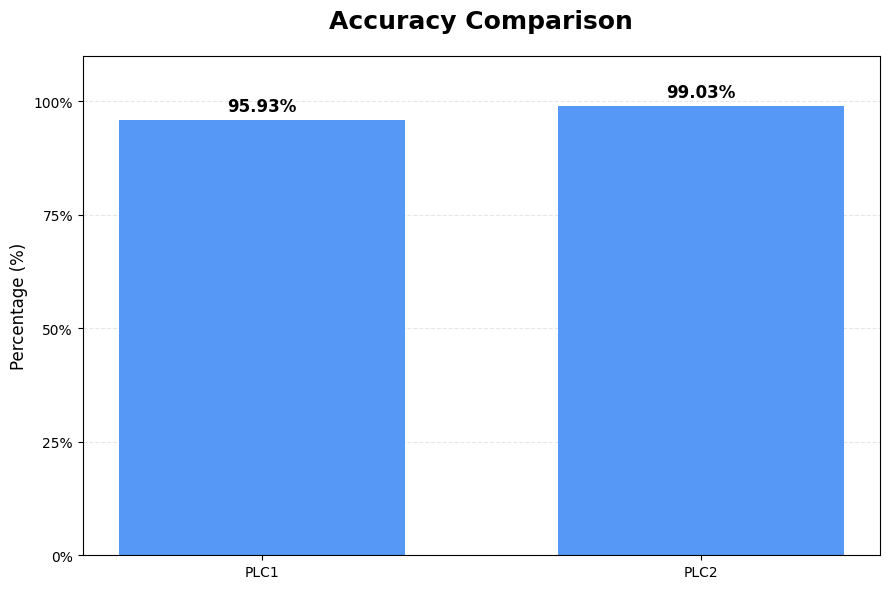

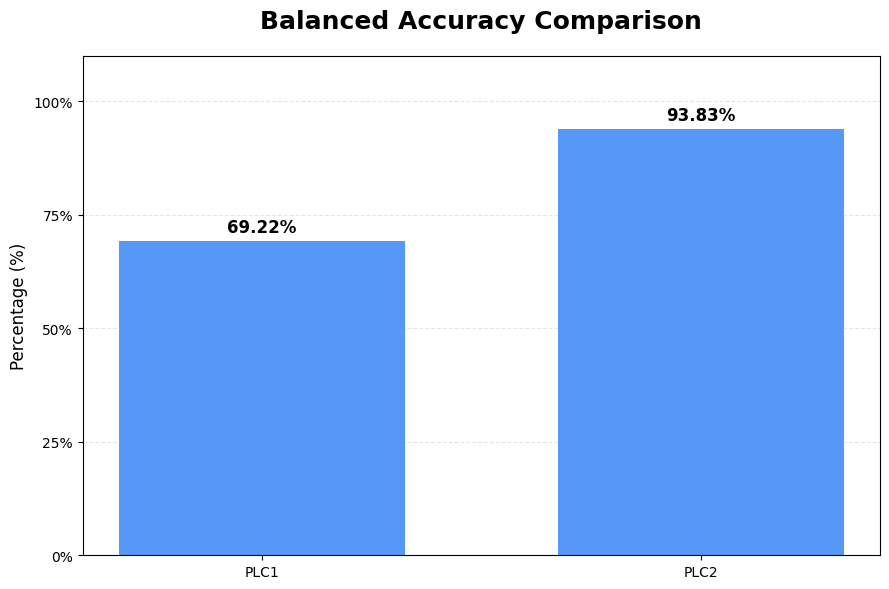

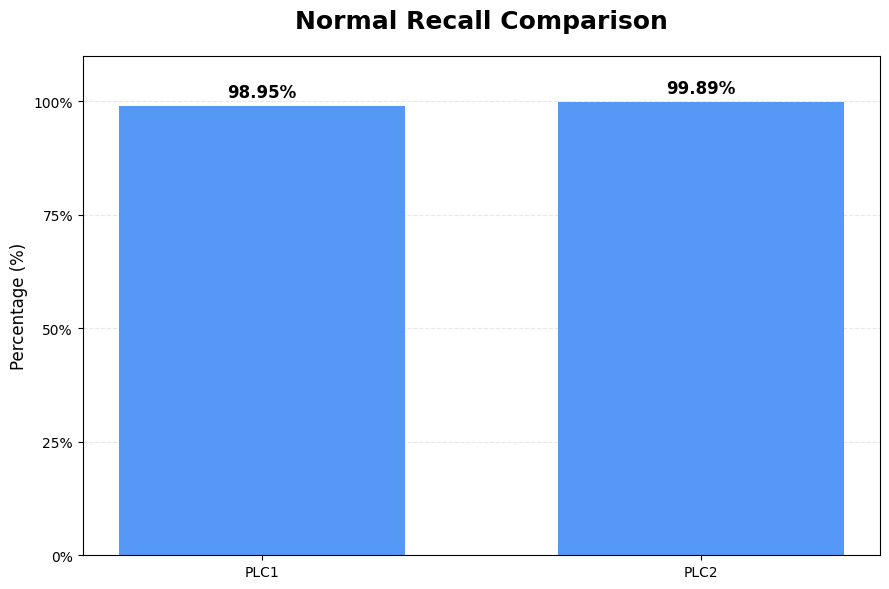

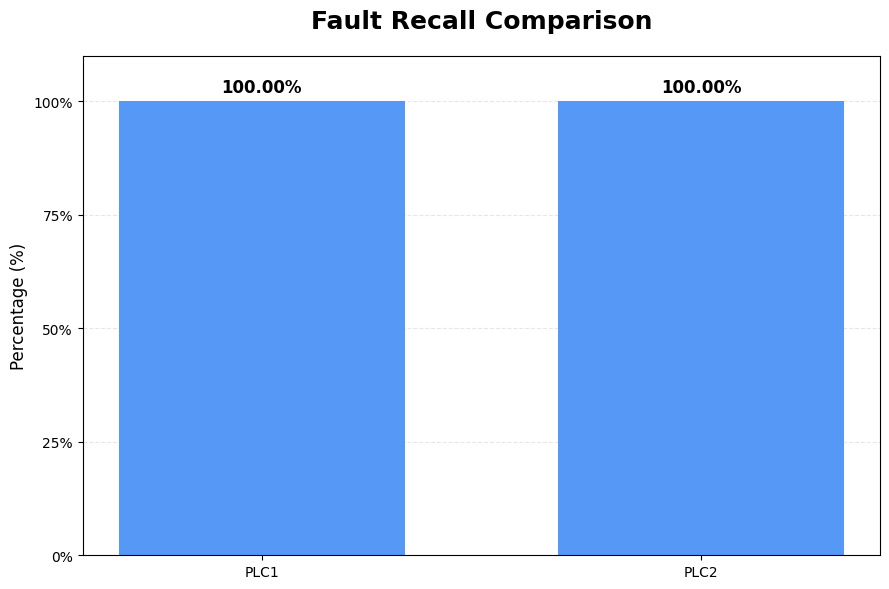

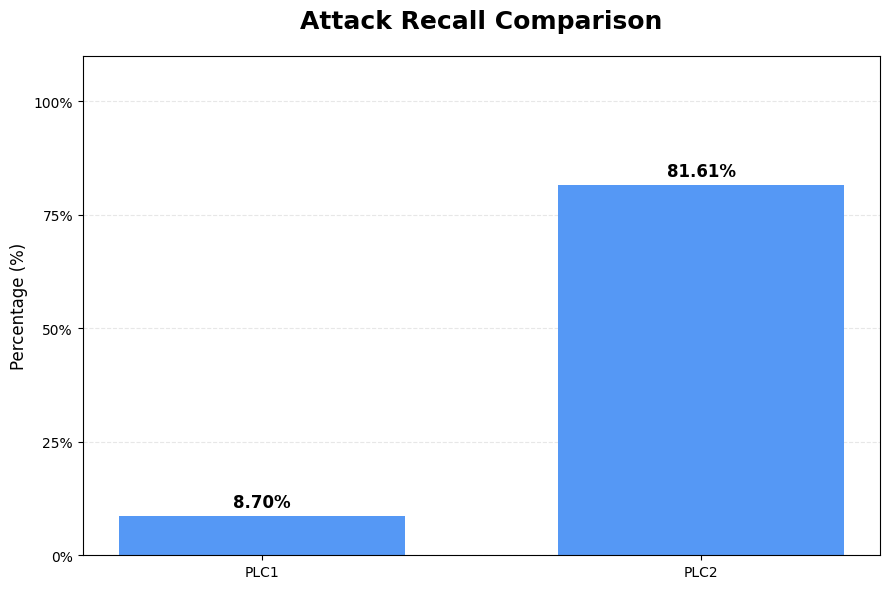

All 5 SVG charts saved successfully!


In [40]:
import matplotlib.pyplot as plt
import os

# Create a folder to save SVG charts
os.makedirs("Traditional_Charts", exist_ok=True)

# Metrics to visualize
metrics = [
    "Accuracy",
    "Balanced Accuracy",
    "Normal Recall",
    "Fault Recall",
    "Attack Recall"
]

# Generate one chart for each metric
for metric in metrics:

    values = [
        results_df.loc["PLC1", metric],
        results_df.loc["PLC2", metric]
    ]

    plt.figure(figsize=(9, 6))

    bars = plt.bar(
        ["PLC1", "PLC2"],
        values,
        color="#5598F5",
        width=0.65
    )

    plt.title(
        f"{metric} Comparison",
        fontsize=18,
        fontweight="bold",
        pad=20
    )

    plt.ylabel("Percentage (%)", fontsize=12)
    plt.ylim(0, 110)

    plt.yticks(range(0, 101, 25),
               [f"{i}%" for i in range(0, 101, 25)])

    plt.grid(axis="y", linestyle="--", alpha=0.3)
    plt.gca().set_axisbelow(True)

    # Display percentage values above bars
    for bar, value in zip(bars, values):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 2,
            f"{value:.2f}%",
            ha="center",
            fontsize=12,
            fontweight="bold"
        )

    plt.tight_layout()

    # Save as SVG
    file_name = f"Traditional_Charts/{metric.replace(' ', '_')}.svg"
    plt.savefig(file_name, format="svg", bbox_inches="tight")

    plt.show()
    plt.close()

print("All 5 SVG charts saved successfully!")

In [2]:
%pip install -q llama-cpp-python

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done


In [3]:
from llama_cpp import Llama

print("llama.cpp imported successfully!")

llama.cpp imported successfully!


In [6]:
%pip uninstall -y llama-cpp-python

%pip install llama-cpp-python \
--extra-index-url https://abetlen.github.io/llama-cpp-python/whl/cu130

Found existing installation: llama_cpp_python 0.3.36
Uninstalling llama_cpp_python-0.3.36:
  Successfully uninstalled llama_cpp_python-0.3.36
Looking in indexes: https://pypi.org/simple, https://abetlen.github.io/llama-cpp-python/whl/cu130
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 782.8/782.8 MB 35.7 MB/s  0:00:17


In [2]:
import llama_cpp
import torch

print("GPU Available:", torch.cuda.is_available())

print("\nllama.cpp System Information:")
print(llama_cpp.llama_cpp.llama_print_system_info().decode())

ggml_cuda_init: found 1 CUDA devices (Total VRAM: 14912 MiB):
  Device 0: Tesla T4, compute capability 7.5, VMM: yes, VRAM: 14912 MiB


GPU Available: True

llama.cpp System Information:
CUDA : ARCHS = 750,800,860,890,900 | FORCE_MMQ = 1 | USE_GRAPHS = 1 | FA_QUANTS = q4_0-q4_0,q8_0-q8_0,f16-f16,bf16-bf16 | CPU : SSE3 = 1 | SSSE3 = 1 | AVX = 1 | AVX2 = 1 | F16C = 1 | FMA = 1 | BMI2 = 1 | LLAMAFILE = 1 | REPACK = 1 | 


#xxxxxxxxxxxxxxx

In [6]:
from google.colab import files

uploaded = files.upload()

Saving ICS_dataset.zip to ICS_dataset.zip


In [7]:
import zipfile
import os

zip_path = "/content/ICS_dataset.zip"
extract_path = "/content/ICS_dataset"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction completed!\n")

for root, dirs, files in os.walk(extract_path):
    for file in files:
        if file.endswith(".xlsx"):
            print(os.path.join(root, file))

Extraction completed!

/content/ICS_dataset/ICS_dataset/faultSensor/faults_snapshots_PLC1.xlsx
/content/ICS_dataset/ICS_dataset/faultSensor/faults_snapshots_PLC2.xlsx
/content/ICS_dataset/ICS_dataset/attack/attack_snapshots_PLC2.xlsx
/content/ICS_dataset/ICS_dataset/attack/attack_snapshots_PLC1.xlsx
/content/ICS_dataset/ICS_dataset/normalSensor/normal_snapshots_PLC2.xlsx
/content/ICS_dataset/ICS_dataset/normalSensor/normal_snapshots_PLC1.xlsx


In [14]:
datasets = {}

for name, path in file_paths.items():

    raw_df = pd.read_excel(
        path,
        engine="openpyxl",
        dtype=str,
        header=None
    )

    # Read column names according to the file format
    first_row = raw_df.iloc[0].dropna().astype(str).tolist()

    if len(first_row) == 1:
        column_names = first_row[0].split(",")
    else:
        column_names = first_row

    column_names = [col.strip() for col in column_names]

    # Remove the empty last column name
    column_names = [col for col in column_names if col != ""]

    # Split the data rows
    df = raw_df.iloc[1:, 0].str.split(",", expand=True)

    # Remove the empty last data column
    df = df.iloc[:, :len(column_names)]

    # Assign column names
    df.columns = column_names

    # Clean values
    df = df.apply(lambda col: col.str.strip())

    datasets[name] = df.reset_index(drop=True)

    print(f"{name}: {df.shape}")
    print("First columns:", df.columns[:4].tolist())

print("\nAll six datasets loaded successfully!")

Normal_PLC1: (81621, 12)
First columns: ['time', 'current_loop', 'loop_latency', 'logic_execution_time']
Normal_PLC2: (81617, 9)
First columns: ['time', 'current_loop', 'loop_latency', 'logic_execution_time']
Fault_PLC1: (14620, 12)
First columns: ['time', 'current_loop', 'loop_latency', 'logic_execution_time']
Fault_PLC2: (14627, 9)
First columns: ['time', 'current_loop', 'loop_latency', 'logic_execution_time']
Attack_PLC1: (3501, 12)
First columns: ['time', 'current_loop', 'loop_latency', 'logic_execution_time']
Attack_PLC2: (4840, 9)
First columns: ['time', 'current_loop', 'loop_latency', 'logic_execution_time']

All six datasets loaded successfully!


In [15]:
processed_datasets = {}

for name, df in datasets.items():
    processed_df = df.copy()

    processed_df["time"] = pd.to_datetime(
        processed_df["time"],
        errors="coerce"
    )

    for col in processed_df.columns:
        if col != "time":
            processed_df[col] = pd.to_numeric(
                processed_df[col],
                errors="coerce"
            )

    processed_datasets[name] = processed_df

    print(
        f"{name}: Missing values = "
        f"{processed_df.isna().sum().sum()}"
    )

print("\nAll datasets processed successfully!")

Normal_PLC1: Missing values = 0
Normal_PLC2: Missing values = 0
Fault_PLC1: Missing values = 0
Fault_PLC2: Missing values = 0
Attack_PLC1: Missing values = 0
Attack_PLC2: Missing values = 0

All datasets processed successfully!


In [16]:
labels = {
    "Normal": 0,
    "Fault": 1,
    "Attack": 2
}

labeled_datasets = {}

for name, df in processed_datasets.items():
    labeled_df = df.copy()

    if name.startswith("Normal"):
        labeled_df["label"] = labels["Normal"]
    elif name.startswith("Fault"):
        labeled_df["label"] = labels["Fault"]
    elif name.startswith("Attack"):
        labeled_df["label"] = labels["Attack"]

    labeled_datasets[name] = labeled_df

    print(f"{name}: {labeled_df.shape}")
    print("Label:", labeled_df["label"].iloc[0])

print("\nLabels assigned successfully!")

Normal_PLC1: (81621, 13)
Label: 0
Normal_PLC2: (81617, 10)
Label: 0
Fault_PLC1: (14620, 13)
Label: 1
Fault_PLC2: (14627, 10)
Label: 1
Attack_PLC1: (3501, 13)
Label: 2
Attack_PLC2: (4840, 10)
Label: 2

Labels assigned successfully!


In [17]:
# Combine datasets for each PLC
PLC1_data = pd.concat([
    labeled_datasets["Normal_PLC1"],
    labeled_datasets["Fault_PLC1"],
    labeled_datasets["Attack_PLC1"]
], ignore_index=True)

PLC2_data = pd.concat([
    labeled_datasets["Normal_PLC2"],
    labeled_datasets["Fault_PLC2"],
    labeled_datasets["Attack_PLC2"]
], ignore_index=True)

# Sort each dataset chronologically
PLC1_data = PLC1_data.sort_values("time").reset_index(drop=True)
PLC2_data = PLC2_data.sort_values("time").reset_index(drop=True)

print("PLC1 shape:", PLC1_data.shape)
print("PLC2 shape:", PLC2_data.shape)

print("\nPLC1 class distribution:")
print(PLC1_data["label"].value_counts().sort_index())

print("\nPLC2 class distribution:")
print(PLC2_data["label"].value_counts().sort_index())

PLC1 shape: (99742, 13)
PLC2 shape: (101084, 10)

PLC1 class distribution:
label
0    81621
1    14620
2     3501
Name: count, dtype: int64

PLC2 class distribution:
label
0    81617
1    14627
2     4840
Name: count, dtype: int64


In [18]:
def chronological_split_by_class(df, train_ratio=0.8):
    train_parts = []
    test_parts = []

    for label in sorted(df["label"].unique()):
        class_data = df[df["label"] == label].sort_values("time")

        split_index = int(len(class_data) * train_ratio)

        train_parts.append(class_data.iloc[:split_index])
        test_parts.append(class_data.iloc[split_index:])

    train_df = pd.concat(train_parts).sort_values("time").reset_index(drop=True)
    test_df = pd.concat(test_parts).sort_values("time").reset_index(drop=True)

    return train_df, test_df


PLC1_train, PLC1_test = chronological_split_by_class(PLC1_data)
PLC2_train, PLC2_test = chronological_split_by_class(PLC2_data)

print("PLC1 Training:", PLC1_train.shape)
print("PLC1 Testing:", PLC1_test.shape)

print("\nPLC2 Training:", PLC2_train.shape)
print("PLC2 Testing:", PLC2_test.shape)

print("\nPLC1 training distribution:")
print(PLC1_train["label"].value_counts().sort_index())

print("\nPLC1 testing distribution:")
print(PLC1_test["label"].value_counts().sort_index())

print("\nPLC2 training distribution:")
print(PLC2_train["label"].value_counts().sort_index())

print("\nPLC2 testing distribution:")
print(PLC2_test["label"].value_counts().sort_index())

PLC1 Training: (79792, 13)
PLC1 Testing: (19950, 13)

PLC2 Training: (80866, 10)
PLC2 Testing: (20218, 10)

PLC1 training distribution:
label
0    65296
1    11696
2     2800
Name: count, dtype: int64

PLC1 testing distribution:
label
0    16325
1     2924
2      701
Name: count, dtype: int64

PLC2 training distribution:
label
0    65293
1    11701
2     3872
Name: count, dtype: int64

PLC2 testing distribution:
label
0    16324
1     2926
2      968
Name: count, dtype: int64


In [19]:
# Separate features (X) and target labels (y)

def prepare_features(train_df, test_df):

    excluded_columns = ["time", "current_loop", "label"]

    X_train = train_df.drop(columns=excluded_columns).copy()
    X_test = test_df.drop(columns=excluded_columns).copy()

    y_train = train_df["label"].copy()
    y_test = test_df["label"].copy()

    # Detect constant features using training data only
    constant_features = [
        col for col in X_train.columns
        if X_train[col].nunique() <= 1
    ]

    # Remove the same constant features from train and test
    X_train = X_train.drop(columns=constant_features)
    X_test = X_test.drop(columns=constant_features)

    return X_train, X_test, y_train, y_test, constant_features


X_train_PLC1, X_test_PLC1, y_train_PLC1, y_test_PLC1, constant_PLC1 = prepare_features(
    PLC1_train, PLC1_test
)

X_train_PLC2, X_test_PLC2, y_train_PLC2, y_test_PLC2, constant_PLC2 = prepare_features(
    PLC2_train, PLC2_test
)

print("PLC1:")
print("Training:", X_train_PLC1.shape)
print("Testing:", X_test_PLC1.shape)
print("Constant features removed:", constant_PLC1)

print("\nPLC2:")
print("Training:", X_train_PLC2.shape)
print("Testing:", X_test_PLC2.shape)
print("Constant features removed:", constant_PLC2)

PLC1:
Training: (79792, 9)
Testing: (19950, 9)
Constant features removed: ['tank_input_valve_mode(1)']

PLC2:
Training: (80866, 7)
Testing: (20218, 7)
Constant features removed: []


In [20]:
traditional_data = {
    "PLC1": {
        "X_train": X_train_PLC1.copy(),
        "X_test": X_test_PLC1.copy(),
        "y_train": y_train_PLC1.copy(),
        "y_test": y_test_PLC1.copy()
    },
    "PLC2": {
        "X_train": X_train_PLC2.copy(),
        "X_test": X_test_PLC2.copy(),
        "y_train": y_train_PLC2.copy(),
        "y_test": y_test_PLC2.copy()
    }
}

for plc, data in traditional_data.items():
    print(f"\n{plc}")
    print("X_train:", data["X_train"].shape)
    print("X_test:", data["X_test"].shape)
    print("y_train:", data["y_train"].shape)
    print("y_test:", data["y_test"].shape)

print("\nTraditional data restored successfully!")


PLC1
X_train: (79792, 9)
X_test: (19950, 9)
y_train: (79792,)
y_test: (19950,)

PLC2
X_train: (80866, 7)
X_test: (20218, 7)
y_train: (80866,)
y_test: (20218,)

Traditional data restored successfully!


In [21]:
import torch
import llama_cpp

print("GPU Available:", torch.cuda.is_available())

print("\nGPU Name:")
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Not Available")

print("\nllama.cpp System Information:")
print(llama_cpp.llama_cpp.llama_print_system_info().decode())

GPU Available: True

GPU Name:
Tesla T4

llama.cpp System Information:
CUDA : ARCHS = 750,800,860,890,900 | FORCE_MMQ = 1 | USE_GRAPHS = 1 | FA_QUANTS = q4_0-q4_0,q8_0-q8_0,f16-f16,bf16-bf16 | CPU : SSE3 = 1 | SSSE3 = 1 | AVX = 1 | AVX2 = 1 | F16C = 1 | FMA = 1 | BMI2 = 1 | LLAMAFILE = 1 | REPACK = 1 | 


###Downloading the Local LLM (Qwen2.5-3B-Instruct)

In [22]:
from huggingface_hub import hf_hub_download

model_path = hf_hub_download(
    repo_id="Qwen/Qwen2.5-3B-Instruct-GGUF",
    filename="qwen2.5-3b-instruct-q4_k_m.gguf"
)

print("Model downloaded successfully!")
print("Model path:", model_path)

qwen2.5-3b-instruct-q4_k_m.gguf: reconstructing file:   0%|          |  0.00B / 2.10GB            

qwen2.5-3b-instruct-q4_k_m.gguf: downloading bytes:           |  0.00B            

Model downloaded successfully!
Model path: /root/.cache/huggingface/hub/models--Qwen--Qwen2.5-3B-Instruct-GGUF/snapshots/7dabda4d13d513e3e842b20f0d435c732f172cbe/qwen2.5-3b-instruct-q4_k_m.gguf


###Loading the Local LLM on GPU

In [23]:
from llama_cpp import Llama

llm = Llama(
    model_path=model_path,
    n_gpu_layers=-1,
    n_ctx=4096,
    n_batch=512,
    verbose=True
)

print("Local LLM loaded successfully!")

llama_model_loader: loaded meta data with 26 key-value pairs and 435 tensors from /root/.cache/huggingface/hub/models--Qwen--Qwen2.5-3B-Instruct-GGUF/snapshots/7dabda4d13d513e3e842b20f0d435c732f172cbe/qwen2.5-3b-instruct-q4_k_m.gguf (version GGUF V3 (latest))
llama_model_loader: Dumping metadata keys/values. Note: KV overrides do not apply in this output.
llama_model_loader: - kv   0:                       general.architecture str              = qwen2
llama_model_loader: - kv   1:                               general.type str              = model
llama_model_loader: - kv   2:                               general.name str              = qwen2.5-3b-instruct
llama_model_loader: - kv   3:                            general.version str              = v0.1-v0.1
llama_model_loader: - kv   4:                           general.finetune str              = qwen2.5-3b-instruct
llama_model_loader: - kv   5:                         general.size_label str              = 3.4B
llama_model_loader: - k

Local LLM loaded successfully!



Using chat eos_token: <|im_end|>
Using chat bos_token: <|endoftext|>


In [24]:
response = llm.create_chat_completion(
    messages=[
        {
            "role": "user",
            "content": "You are an AI data preprocessing assistant. Briefly introduce yourself."
        }
    ],
    max_tokens=100,
    temperature=0.2
)

print(response["choices"][0]["message"]["content"])

CUDA Graph id 24 reused
ggml_backend_cuda_graph_compute: CUDA graph warmup complete
CUDA Graph id 24 reused
CUDA Graph id 24 reused
CUDA Graph id 24 reused
CUDA Graph id 24 reused
CUDA Graph id 24 reused
CUDA Graph id 24 reused
CUDA Graph id 24 reused
CUDA Graph id 24 reused
CUDA Graph id 24 reused
CUDA Graph id 24 reused
CUDA Graph id 24 reused
CUDA Graph id 24 reused
CUDA Graph id 24 reused
CUDA Graph id 24 reused
CUDA Graph id 24 reused
CUDA Graph id 24 reused
CUDA Graph id 24 reused
CUDA Graph id 24 reused
CUDA Graph id 24 reused
CUDA Graph id 24 reused
CUDA Graph id 24 reused
CUDA Graph id 24 reused
CUDA Graph id 24 reused
CUDA Graph id 24 reused
CUDA Graph id 24 reused
CUDA Graph id 24 reused
CUDA Graph id 24 reused
CUDA Graph id 24 reused
CUDA Graph id 24 reused
CUDA Graph id 24 reused
CUDA Graph id 24 reused
CUDA Graph id 24 reused
CUDA Graph id 24 reused
CUDA Graph id 24 reused
CUDA Graph id 24 reused
CUDA Graph id 24 reused
CUDA Graph id 24 reused
CUDA Graph id 24 reused
CUDA

Hello! I am Qwen, an AI assistant created by Alibaba Cloud. My primary function is to assist with data preprocessing tasks, helping to clean, organize, and prepare data for analysis or machine learning models. I can handle various data types and formats, and I'm here to help ensure your data is in the best possible state for your projects. How can I assist you today with your data preprocessing needs?


Step 1: تجهيز أدوات فحص البيانات

In [25]:
import pandas as pd
import numpy as np

def inspect_training_data(X_train, y_train, dataset_name):

    print(f"\n{'='*50}")
    print(f"Dataset: {dataset_name}")
    print(f"{'='*50}")

    print("\n1. Dataset Shape:")
    print("Rows:", X_train.shape[0])
    print("Features:", X_train.shape[1])

    print("\n2. Data Types:")
    print(X_train.dtypes)

    print("\n3. Missing Values:")
    print(X_train.isnull().sum())

    print("\n4. Constant Features:")
    constant_features = [
        col for col in X_train.columns
        if X_train[col].nunique(dropna=False) <= 1
    ]
    print(constant_features if constant_features else "None")

    print("\n5. Statistical Summary:")
    print(X_train.describe().round(3))

    print("\n6. Class Distribution:")
    print(
        pd.Series(y_train)
        .value_counts()
        .sort_index()
        .rename(index={
            0: "Normal",
            1: "Fault",
            2: "Attack"
        })
    )

    return {
        "shape": X_train.shape,
        "missing_values": X_train.isnull().sum().to_dict(),
        "constant_features": constant_features,
        "class_distribution": pd.Series(y_train).value_counts().to_dict()
    }


# Inspect PLC1 training data
PLC1_summary = inspect_training_data(
    traditional_data["PLC1"]["X_train"],
    traditional_data["PLC1"]["y_train"],
    "PLC1"
)

# Inspect PLC2 training data
PLC2_summary = inspect_training_data(
    traditional_data["PLC2"]["X_train"],
    traditional_data["PLC2"]["y_train"],
    "PLC2"
)


Dataset: PLC1

1. Dataset Shape:
Rows: 79792
Features: 9

2. Data Types:
loop_latency                     int64
logic_execution_time             int64
tank_input_valve_status(0)     float64
tank_level_value(2)            float64
tank_level_min(3)              float64
tank_level_max(4)              float64
tank_output_valve_status(5)    float64
tank_output_valve_mode(6)      float64
tank_output_flow_value(7)      float64
dtype: object

3. Missing Values:
loop_latency                   0
logic_execution_time           0
tank_input_valve_status(0)     0
tank_level_value(2)            0
tank_level_min(3)              0
tank_level_max(4)              0
tank_output_valve_status(5)    0
tank_output_valve_mode(6)      0
tank_output_flow_value(7)      0
dtype: int64

4. Constant Features:
None

5. Statistical Summary:
       loop_latency  logic_execution_time  tank_input_valve_status(0)  \
count     79792.000             79792.000                   79792.000   
mean         74.534             

Step 2: فحص الأعمدة والقيم المتطرفة

In [26]:
def detailed_feature_check(X_train, dataset_name):

    print(f"\n{'='*60}")
    print(f"Detailed Feature Check: {dataset_name}")
    print(f"{'='*60}")

    for col in X_train.columns:

        values = X_train[col]

        Q1 = values.quantile(0.25)
        Q3 = values.quantile(0.75)
        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outliers = (
            (values < lower_bound) |
            (values > upper_bound)
        ).sum()

        print(f"\nFeature: {col}")
        print("Unique values:", values.nunique(dropna=False))
        print("Min:", values.min())
        print("Max:", values.max())
        print("IQR outliers:", outliers)
        print("Outlier percentage:", round(outliers / len(values) * 100, 2), "%")


detailed_feature_check(
    traditional_data["PLC1"]["X_train"],
    "PLC1"
)

detailed_feature_check(
    traditional_data["PLC2"]["X_train"],
    "PLC2"
)


Detailed Feature Check: PLC1

Feature: loop_latency
Unique values: 1802
Min: 0
Max: 36872
IQR outliers: 4549
Outlier percentage: 5.7 %

Feature: logic_execution_time
Unique values: 1878
Min: 0
Max: 37157
IQR outliers: 3887
Outlier percentage: 4.87 %

Feature: tank_input_valve_status(0)
Unique values: 2
Min: 0.0
Max: 1.0
IQR outliers: 0
Outlier percentage: 0.0 %

Feature: tank_level_value(2)
Unique values: 57605
Min: 0.9966666666620654
Max: 10.0
IQR outliers: 0
Outlier percentage: 0.0 %

Feature: tank_level_min(3)
Unique values: 493
Min: 1.0
Max: 8.0
IQR outliers: 235
Outlier percentage: 0.29 %

Feature: tank_level_max(4)
Unique values: 494
Min: 1.0
Max: 8.9984
IQR outliers: 588
Outlier percentage: 0.74 %

Feature: tank_output_valve_status(5)
Unique values: 2
Min: 0.0
Max: 1.0
IQR outliers: 0
Outlier percentage: 0.0 %

Feature: tank_output_valve_mode(6)
Unique values: 2
Min: 1.0
Max: 3.0
IQR outliers: 640
Outlier percentage: 0.8 %

Feature: tank_output_flow_value(7)
Unique values: 2
Mi

Step 3: إعطاء البيانات للـ Local AI Agent

In [30]:
import json

def create_agent_report(X_train, y_train, dataset_name):

    report = {
        "dataset": dataset_name,
        "rows": len(X_train),
        "features": {}
    }

    for col in X_train.columns:
        values = X_train[col]

        Q1 = values.quantile(0.25)
        Q3 = values.quantile(0.75)
        IQR = Q3 - Q1

        outliers = (
            (values < Q1 - 1.5 * IQR) |
            (values > Q3 + 1.5 * IQR)
        ).sum()

        report["features"][col] = {
            "data_type": str(values.dtype),
            "unique_values": int(values.nunique()),
            "min": float(values.min()),
            "max": float(values.max()),
            "mean": float(values.mean()),
            "std": float(values.std()),
            "outlier_percentage": round(
                outliers / len(values) * 100, 2
            )
        }

    report["class_distribution"] = {
        str(k): int(v)
        for k, v in pd.Series(y_train).value_counts().sort_index().items()
    }

    return report


# Only training data is provided to the agent
agent_reports = {
    "PLC1": create_agent_report(
        traditional_data["PLC1"]["X_train"],
        traditional_data["PLC1"]["y_train"],
        "PLC1"
    ),
    "PLC2": create_agent_report(
        traditional_data["PLC2"]["X_train"],
        traditional_data["PLC2"]["y_train"],
        "PLC2"
    )
}


# Improved prompt for the AI Agent
prompt = f"""
You are an expert AI data preprocessing agent specialized in
Industrial Control Systems (ICS) and industrial sensor data.

Analyze the training data reports for PLC1 and PLC2.

IMPORTANT RULES:

1. Use only the numerical statistics provided in the reports.
2. Never invent values, statistics, or feature properties.
3. Do not assume that outliers are errors.
4. Do not recommend deleting outliers based only on IQR.
5. Do not remove features because they have low variance or few unique values.
6. Do not classify features as categorical based only on unique-value counts.
7. Do not recommend scaling automatically. Consider the intended model.
8. Do not recommend SMOTE or oversampling without discussing
   the risks for industrial time-series data.
9. Do not recommend irreversible preprocessing without strong evidence.
10. If information is insufficient, state:
    "Further investigation required".

MANDATORY ANALYSIS:

For EACH PLC, complete all the following tasks:

A. GENERAL DATA OBSERVATIONS:
- Report the number of training rows and features.
- Identify any confirmed missing values or constant features
  only if the report provides this information.
- Do not claim that missing values or constant features exist
  unless supported by the report.

B. FEATURE-BY-FEATURE OUTLIER ANALYSIS:
- Examine EVERY feature individually.
- Report its exact outlier percentage from the report.
- Identify features with relatively high outlier percentages.
- Distinguish between statistical outliers and actual data errors.
- Explain why unusual values may be important in ICS.
- Never conclude that a feature has zero outliers unless
  its reported percentage is exactly 0%.

C. CLASS IMBALANCE ANALYSIS:
- Report the exact number of samples for each class.
- Identify the majority and minority classes.
- Calculate the percentage of each class using the provided counts.
- Explain how class imbalance may affect Attack detection.
- Discuss whether class weighting may be worth investigating.
- Do not recommend oversampling automatically.

D. PREPROCESSING RECOMMENDATIONS:
- Recommend only actions supported by the available evidence.
- For each recommendation, explain the evidence and possible risk.
- If no preprocessing action is justified, explicitly state
  "No preprocessing action justified at this stage".
- Do not confuse a recommendation for further investigation
  with a confirmed preprocessing requirement.

E. FURTHER INVESTIGATION:
- Identify missing information needed to make reliable decisions.
- Consider feature meaning, industrial operating ranges,
  temporal behavior, and the relationship between sensor values
  and attack or fault labels.

OUTPUT REQUIREMENTS:

Return valid JSON only.
Do not include Markdown or text outside the JSON.
Do not generate Python code.
Do not modify the data.

Use this exact structure:

{{
  "PLC1": {{
    "general_observations": [],
    "feature_analysis": [
      {{
        "feature": "",
        "outlier_percentage": 0,
        "interpretation": "",
        "recommended_action": ""
      }}
    ],
    "class_imbalance": {{
      "class_counts": {{}},
      "class_percentages": {{}},
      "impact_on_attack_detection": "",
      "possible_action": ""
    }},
    "preprocessing_recommendations": [
      {{
        "action": "",
        "features": [],
        "evidence": "",
        "reason": "",
        "risk": "",
        "confidence": "High/Medium/Low"
      }}
    ],
    "further_investigation": []
  }},
  "PLC2": {{
    "general_observations": [],
    "feature_analysis": [
      {{
        "feature": "",
        "outlier_percentage": 0,
        "interpretation": "",
        "recommended_action": ""
      }}
    ],
    "class_imbalance": {{
      "class_counts": {{}},
      "class_percentages": {{}},
      "impact_on_attack_detection": "",
      "possible_action": ""
    }},
    "preprocessing_recommendations": [
      {{
        "action": "",
        "features": [],
        "evidence": "",
        "reason": "",
        "risk": "",
        "confidence": "High/Medium/Low"
      }}
    ],
    "further_investigation": []
  }}
}}

IMPORTANT:
- Include every feature in feature_analysis.
- Do not skip features with zero outlier percentage.
- Use exact values from the reports.
- Calculate class percentages from the provided class counts.
- Do not invent additional statistics.

TRAINING REPORTS:
{json.dumps(agent_reports, indent=2)}
"""


# Ask the local LLM to analyze the reports
response = llm.create_chat_completion(
    messages=[
        {"role": "user", "content": prompt}
    ],
    temperature=0.1,
    max_tokens=1800
)

agent_recommendations_v2 = response["choices"][0]["message"]["content"]

print(agent_recommendations_v2)

Llama.generate: 40 prefix-match hit, remaining 2825 prompt tokens to eval
CUDA Graph id 99 reused
ggml_backend_cuda_graph_compute: CUDA graph warmup complete
CUDA Graph id 99 reused
CUDA Graph id 99 reused
CUDA Graph id 99 reused
CUDA Graph id 99 reused
CUDA Graph id 99 reused
CUDA Graph id 99 reused
CUDA Graph id 99 reused
CUDA Graph id 99 reused
CUDA Graph id 99 reused
CUDA Graph id 99 reused
CUDA Graph id 99 reused
CUDA Graph id 99 reused
CUDA Graph id 99 reused
CUDA Graph id 99 reused
CUDA Graph id 99 reused
CUDA Graph id 99 reused
CUDA Graph id 99 reused
CUDA Graph id 99 reused
CUDA Graph id 99 reused
CUDA Graph id 99 reused
CUDA Graph id 99 reused
CUDA Graph id 99 reused
CUDA Graph id 99 reused
CUDA Graph id 99 reused
CUDA Graph id 99 reused
CUDA Graph id 99 reused
CUDA Graph id 99 reused
CUDA Graph id 99 reused
CUDA Graph id 99 reused
CUDA Graph id 99 reused
CUDA Graph id 99 reused
CUDA Graph id 99 reused
CUDA Graph id 99 reused
CUDA Graph id 99 reused
CUDA Graph id 99 reused
CU

```json
{
  "PLC1": {
    "general_observations": [],
    "feature_analysis": [
      {
        "feature": "loop_latency",
        "outlier_percentage": 5.7,
        "interpretation": "5.7% of the data points are considered outliers based on the provided report.",
        "recommended_action": ""
      },
      {
        "feature": "logic_execution_time",
        "outlier_percentage": 4.87,
        "interpretation": "4.87% of the data points are considered outliers based on the provided report.",
        "recommended_action": ""
      },
      {
        "feature": "tank_input_valve_status(0)",
        "outlier_percentage": 0.0,
        "interpretation": "0.0% of the data points are considered outliers based on the provided report.",
        "recommended_action": ""
      },
      {
        "feature": "tank_level_value(2)",
        "outlier_percentage": 0.0,
        "interpretation": "0.0% of the data points are considered outliers based on the provided report.",
        "recommended_ac

In [31]:
response = llm.create_chat_completion(
    messages=[
        {"role": "user", "content": prompt}
    ],
    temperature=0.1,
    max_tokens=3000
)

agent_recommendations_v3 = response["choices"][0]["message"]["content"]

print(agent_recommendations_v3)

Llama.generate: 2864 prefix-match hit, remaining 1 prompt tokens to eval
ggml_backend_cuda_graph_compute: CUDA graph warmup reset
CUDA Graph id 114 reused
ggml_backend_cuda_graph_compute: CUDA graph warmup complete
CUDA Graph id 114 reused
CUDA Graph id 114 reused
CUDA Graph id 114 reused
CUDA Graph id 114 reused
CUDA Graph id 114 reused
CUDA Graph id 114 reused
CUDA Graph id 114 reused
CUDA Graph id 114 reused
CUDA Graph id 114 reused
CUDA Graph id 114 reused
CUDA Graph id 114 reused
CUDA Graph id 114 reused
CUDA Graph id 114 reused
CUDA Graph id 114 reused
CUDA Graph id 114 reused
CUDA Graph id 114 reused
CUDA Graph id 114 reused
CUDA Graph id 114 reused
CUDA Graph id 114 reused
CUDA Graph id 114 reused
CUDA Graph id 114 reused
CUDA Graph id 114 reused
CUDA Graph id 114 reused
CUDA Graph id 114 reused
CUDA Graph id 114 reused
CUDA Graph id 114 reused
CUDA Graph id 114 reused
CUDA Graph id 114 reused
CUDA Graph id 114 reused
CUDA Graph id 114 reused
CUDA Graph id 114 reused
CUDA Graph

```json
{
  "PLC1": {
    "general_observations": [
      {
        "rows": 79792,
        "features": 18
      }
    ],
    "feature_analysis": [
      {
        "feature": "loop_latency",
        "outlier_percentage": 5.7,
        "interpretation": "5.7% of the data points are considered outliers based on the report.",
        "recommended_action": ""
      },
      {
        "feature": "logic_execution_time",
        "outlier_percentage": 4.87,
        "interpretation": "4.87% of the data points are considered outliers based on the report.",
        "recommended_action": ""
      },
      {
        "feature": "tank_input_valve_status(0)",
        "outlier_percentage": 0.0,
        "interpretation": "0.0% of the data points are considered outliers based on the report.",
        "recommended_action": ""
      },
      {
        "feature": "tank_level_value(2)",
        "outlier_percentage": 0.0,
        "interpretation": "0.0% of the data points are considered outliers based on the re

Validation

In [32]:
import json
import re

# 1. Read the AI Agent output
output = agent_recommendations_v3.strip()

# Remove Markdown JSON fences if present
output = re.sub(r"^```json\s*", "", output)
output = re.sub(r"\s*```$", "", output)

print("AI Agent output length:", len(output))
print("Output ending:", output[-150:])

# 2. Parse JSON
try:
    agent_result = json.loads(output)
    print("\nJSON parsed successfully!")

except json.JSONDecodeError as e:
    print("\nJSON parsing failed!")
    print("Error:", e)
    print("\nThe output may be incomplete or invalid.")
    agent_result = None

# 3. Validate results if JSON is valid
if agent_result is not None:

    for plc in ["PLC1", "PLC2"]:

        print("\n" + "=" * 55)
        print(f"VALIDATION RESULTS: {plc}")
        print("=" * 55)

        actual_report = agent_reports[plc]
        actual_features = actual_report["features"]

        # Find the corresponding AI Agent section
        agent_plc = agent_result.get(plc, {})

        # Check feature count
        expected_count = len(actual_features)
        reported_count = agent_plc.get(
            "general_observations", [{}]
        )[0].get("features")

        print(f"\nExpected feature count: {expected_count}")
        print(f"AI Agent feature count: {reported_count}")
        print("Feature count:",
              "PASS" if reported_count == expected_count else "FAIL")

        # Check feature coverage
        agent_features = agent_plc.get("feature_analysis", [])
        agent_feature_names = {
            item.get("feature") for item in agent_features
        }

        expected_feature_names = set(actual_features.keys())

        missing = expected_feature_names - agent_feature_names
        extra = agent_feature_names - expected_feature_names

        print("\nMissing features:", missing if missing else "None")
        print("Unexpected features:", extra if extra else "None")

        # Check outlier percentages
        print("\nOUTLIER PERCENTAGE CHECK")

        for feature, stats in actual_features.items():

            expected = stats["outlier_percentage"]

            agent_item = next(
                (item for item in agent_features
                 if item.get("feature") == feature),
                None
            )

            if agent_item is None:
                print(f"{feature}: FAIL - Missing from AI output")
                continue

            reported = agent_item.get("outlier_percentage")

            if reported is None:
                print(f"{feature}: FAIL - Percentage not provided")
                continue

            passed = abs(float(reported) - expected) <= 0.1

            print(
                f"{feature}: Actual={expected}% | "
                f"AI={reported}% | "
                f"{'PASS' if passed else 'FAIL'}"
            )

        # Check class distribution
        print("\nCLASS DISTRIBUTION CHECK")

        expected_classes = actual_report["class_distribution"]
        agent_classes = agent_plc.get("class_imbalance", {}).get(
            "class_distribution", {}
        )

        for label, count in expected_classes.items():

            agent_count = agent_classes.get(label)

            passed = agent_count is not None and int(agent_count) == count

            print(
                f"Class {label}: Expected={count} | "
                f"AI={agent_count} | "
                f"{'PASS' if passed else 'FAIL'}"
            )

AI Agent output length: 4864
Output ending: nded_action": ""
      },
      {
        "feature": "bottle_level_max(11)",
        "outlier_percentage": 0.0,
        "interpretation": "0.0% of the

JSON parsing failed!
Error: Unterminated string starting at: line 134 column 27 (char 4852)

The output may be incomplete or invalid.


In [33]:
import json

plc1_prompt = f"""
Analyze this ICS training dataset report:

{json.dumps(agent_reports["PLC1"], indent=2)}

Return ONLY valid JSON with this exact structure:

{{
  "dataset": "PLC1",
  "reported_feature_count": 0,
  "feature_analysis": [
    {{
      "feature": "exact feature name",
      "outlier_percentage": 0.0,
      "interpretation": "brief observation",
      "recommended_action": "brief action or none"
    }}
  ],
  "class_imbalance": {{
    "class_counts": {{}},
    "impact": "brief explanation",
    "recommendation": "brief recommendation"
  }},
  "overall_recommendation": "brief recommendation",
  "further_investigation": ["item 1", "item 2"]
}}

Rules:
- Include all 9 features exactly as provided.
- Copy outlier percentages from the report; do not estimate them.
- Copy class counts exactly.
- Do not invent data or feature properties.
- Do not recommend deleting outliers without strong evidence.
- Keep every explanation under 20 words.
- Do not perform preprocessing.
- Return complete valid JSON only. No Markdown.
"""

response_plc1 = llm.create_chat_completion(
    messages=[{"role": "user", "content": plc1_prompt}],
    max_tokens=1800,
    temperature=0.1
)

agent_plc1_output = response_plc1["choices"][0]["message"]["content"]

print(agent_plc1_output)

Llama.generate: 24 prefix-match hit, remaining 1304 prompt tokens to eval
CUDA Graph id 138 reused
ggml_backend_cuda_graph_compute: CUDA graph warmup complete
CUDA Graph id 138 reused
CUDA Graph id 138 reused
CUDA Graph id 138 reused
CUDA Graph id 138 reused
CUDA Graph id 138 reused
CUDA Graph id 138 reused
CUDA Graph id 138 reused
CUDA Graph id 138 reused
CUDA Graph id 138 reused
CUDA Graph id 138 reused
CUDA Graph id 138 reused
CUDA Graph id 138 reused
CUDA Graph id 138 reused
CUDA Graph id 138 reused
CUDA Graph id 138 reused
CUDA Graph id 138 reused
CUDA Graph id 138 reused
CUDA Graph id 138 reused
CUDA Graph id 138 reused
CUDA Graph id 138 reused
CUDA Graph id 138 reused
CUDA Graph id 138 reused
CUDA Graph id 138 reused
CUDA Graph id 138 reused
CUDA Graph id 138 reused
CUDA Graph id 138 reused
CUDA Graph id 138 reused
CUDA Graph id 138 reused
CUDA Graph id 138 reused
CUDA Graph id 138 reused
CUDA Graph id 138 reused
CUDA Graph id 138 reused
CUDA Graph id 138 reused
CUDA Graph id 13

{
  "dataset": "PLC1",
  "reported_feature_count": 9,
  "feature_analysis": [
    {
      "feature": "loop_latency",
      "outlier_percentage": 5.7,
      "interpretation": "High variability in loop latency times.",
      "recommended_action": "Monitor for anomalies."
    },
    {
      "feature": "logic_execution_time",
      "outlier_percentage": 4.87,
      "interpretation": "Moderate variability in logic execution times.",
      "recommended_action": "Consider outlier removal."
    },
    {
      "feature": "tank_input_valve_status(0)",
      "outlier_percentage": 0.0,
      "interpretation": "No outliers detected.",
      "recommended_action": "No action needed."
    },
    {
      "feature": "tank_level_value(2)",
      "outlier_percentage": 0.0,
      "interpretation": "No outliers detected.",
      "recommended_action": "No action needed."
    },
    {
      "feature": "tank_level_min(3)",
      "outlier_percentage": 0.29,
      "interpretation": "Low outliers detected.",
    

In [34]:
import json

# Parse the AI Agent output
result = json.loads(agent_plc1_output)

# Expected information from the original training report
actual_report = agent_reports["PLC1"]
actual_features = actual_report["features"]
actual_classes = actual_report["class_distribution"]

validation_results = []

# 1. Validate feature count
reported_count = result.get("reported_feature_count")
expected_count = len(actual_features)

validation_results.append({
    "check": "Feature count",
    "status": "PASS" if reported_count == expected_count else "FAIL",
    "details": f"Expected {expected_count}, received {reported_count}"
})

# 2. Validate feature names and outlier percentages
agent_features = {
    item["feature"]: item
    for item in result.get("feature_analysis", [])
}

for feature, stats in actual_features.items():

    item = agent_features.get(feature)

    if item is None:
        validation_results.append({
            "check": f"Feature: {feature}",
            "status": "FAIL",
            "details": "Feature missing from AI output"
        })
        continue

    expected = stats["outlier_percentage"]
    reported = item.get("outlier_percentage")

    passed = (
        reported is not None
        and abs(float(reported) - expected) <= 0.1
    )

    validation_results.append({
        "check": f"Outliers: {feature}",
        "status": "PASS" if passed else "FAIL",
        "details": f"Expected {expected}%, received {reported}%"
    })

# 3. Validate class counts
reported_classes = result.get(
    "class_imbalance", {}
).get("class_counts", {})

for label, expected_count in actual_classes.items():

    reported_count = reported_classes.get(label)

    passed = (
        reported_count is not None
        and int(reported_count) == expected_count
    )

    validation_results.append({
        "check": f"Class {label} count",
        "status": "PASS" if passed else "FAIL",
        "details": f"Expected {expected_count}, received {reported_count}"
    })

# 4. Detect risky preprocessing recommendations
risky_keywords = [
    "remove outlier",
    "remove outliers",
    "delete outlier",
    "delete outliers",
    "drop outlier",
    "drop outliers"
]

for feature, item in agent_features.items():

    action = item.get("recommended_action", "").lower()

    risky = any(keyword in action for keyword in risky_keywords)

    if risky:
        validation_results.append({
            "check": f"Safety: {feature}",
            "status": "WARNING",
            "details": f"Potentially risky recommendation: {action}"
        })

# 5. Display validation report
print("=" * 65)
print("AI AGENT OUTPUT VALIDATION - PLC1")
print("=" * 65)

for item in validation_results:
    print(f"\n[{item['status']}] {item['check']}")
    print(item["details"])

print("\n" + "=" * 65)

failed = sum(x["status"] == "FAIL" for x in validation_results)
warnings = sum(x["status"] == "WARNING" for x in validation_results)

print("Failed checks:", failed)
print("Safety warnings:", warnings)

if failed == 0 and warnings == 0:
    print("Result: PASSED")
elif failed > 0:
    print("Result: FAILED - Output needs correction")
else:
    print("Result: REVIEW REQUIRED - Human approval needed")

AI AGENT OUTPUT VALIDATION - PLC1

[PASS] Feature count
Expected 9, received 9

[PASS] Outliers: loop_latency
Expected 5.7%, received 5.7%

[PASS] Outliers: logic_execution_time
Expected 4.87%, received 4.87%

[PASS] Outliers: tank_input_valve_status(0)
Expected 0.0%, received 0.0%

[PASS] Outliers: tank_level_value(2)
Expected 0.0%, received 0.0%

[PASS] Outliers: tank_level_min(3)
Expected 0.29%, received 0.29%

[PASS] Outliers: tank_level_max(4)
Expected 0.74%, received 0.74%

[PASS] Outliers: tank_output_valve_status(5)
Expected 0.0%, received 0.0%

[PASS] Outliers: tank_output_valve_mode(6)
Expected 0.8%, received 0.8%

[PASS] Outliers: tank_output_flow_value(7)
Expected 0.0%, received 0.0%

[PASS] Class 0 count
Expected 65296, received 65296

[PASS] Class 1 count
Expected 11696, received 11696

[PASS] Class 2 count
Expected 2800, received 2800

Failed checks: 0
Safety warnings: 0
Result: PASSED


In [35]:
import json

plc2_prompt = f"""
Analyze this ICS training dataset report:

{json.dumps(agent_reports["PLC2"], indent=2)}

Return ONLY valid JSON with this exact structure:

{{
  "dataset": "PLC2",
  "reported_feature_count": 0,
  "feature_analysis": [
    {{
      "feature": "exact feature name",
      "outlier_percentage": 0.0,
      "interpretation": "brief observation",
      "recommended_action": "brief action or none"
    }}
  ],
  "class_imbalance": {{
    "class_counts": {{}},
    "impact": "brief explanation",
    "recommendation": "brief recommendation"
  }},
  "overall_recommendation": "brief recommendation",
  "further_investigation": ["item 1", "item 2"]
}}

Rules:
- Include all 7 features exactly as provided.
- Copy outlier percentages from the report; do not estimate them.
- Copy class counts exactly.
- Do not invent data or feature properties.
- Do not recommend deleting outliers without strong evidence.
- Keep every explanation under 20 words.
- Do not perform preprocessing.
- Return complete valid JSON only. No Markdown.
"""

response_plc2 = llm.create_chat_completion(
    messages=[{"role": "user", "content": plc2_prompt}],
    max_tokens=1800,
    temperature=0.1
)

agent_plc2_output = response_plc2["choices"][0]["message"]["content"]

print(agent_plc2_output)

Llama.generate: 41 prefix-match hit, remaining 1057 prompt tokens to eval
CUDA Graph id 156 reused
ggml_backend_cuda_graph_compute: CUDA graph warmup complete
CUDA Graph id 156 reused
CUDA Graph id 156 reused
CUDA Graph id 156 reused
CUDA Graph id 156 reused
CUDA Graph id 156 reused
CUDA Graph id 156 reused
CUDA Graph id 156 reused
CUDA Graph id 156 reused
CUDA Graph id 156 reused
CUDA Graph id 156 reused
CUDA Graph id 156 reused
CUDA Graph id 156 reused
CUDA Graph id 156 reused
CUDA Graph id 156 reused
CUDA Graph id 156 reused
CUDA Graph id 156 reused
CUDA Graph id 156 reused
CUDA Graph id 156 reused
CUDA Graph id 156 reused
CUDA Graph id 156 reused
CUDA Graph id 156 reused
CUDA Graph id 156 reused
CUDA Graph id 156 reused
CUDA Graph id 156 reused
CUDA Graph id 156 reused
CUDA Graph id 156 reused
CUDA Graph id 156 reused
CUDA Graph id 156 reused
CUDA Graph id 156 reused
CUDA Graph id 156 reused
CUDA Graph id 156 reused
CUDA Graph id 156 reused
CUDA Graph id 156 reused
CUDA Graph id 15

{
  "dataset": "PLC2",
  "reported_feature_count": 7,
  "feature_analysis": [
    {
      "feature": "loop_latency",
      "outlier_percentage": 5.77,
      "interpretation": "High variability, potential outliers.",
      "recommended_action": "Monitor and consider outlier removal."
    },
    {
      "feature": "logic_execution_time",
      "outlier_percentage": 6.21,
      "interpretation": "High variability, potential outliers.",
      "recommended_action": "Monitor and consider outlier removal."
    },
    {
      "feature": "conveyor_belt_engine_status(8)",
      "outlier_percentage": 0.0,
      "interpretation": "No outliers detected.",
      "recommended_action": "No action needed."
    },
    {
      "feature": "conveyor_belt_engine_mode(9)",
      "outlier_percentage": 27.63,
      "interpretation": "High variability, potential outliers.",
      "recommended_action": "Monitor and consider outlier removal."
    },
    {
      "feature": "bottle_level_value(10)",
      "outlier_

In [36]:
import json

# Parse PLC2 output
result = json.loads(agent_plc2_output)

actual_report = agent_reports["PLC2"]
actual_features = actual_report["features"]
actual_classes = actual_report["class_distribution"]

validation_results = []

# 1. Feature count
expected_count = len(actual_features)
reported_count = result.get("reported_feature_count")

validation_results.append({
    "check": "Feature count",
    "status": "PASS" if reported_count == expected_count else "FAIL",
    "details": f"Expected {expected_count}, received {reported_count}"
})

# 2. Feature coverage and outlier percentages
agent_features = {
    item["feature"]: item
    for item in result.get("feature_analysis", [])
}

missing = set(actual_features) - set(agent_features)
extra = set(agent_features) - set(actual_features)

validation_results.append({
    "check": "Feature coverage",
    "status": "PASS" if not missing and not extra else "FAIL",
    "details": f"Missing: {missing}; Extra: {extra}"
})

for feature, stats in actual_features.items():

    item = agent_features.get(feature)

    if item is None:
        continue

    expected = stats["outlier_percentage"]
    reported = item.get("outlier_percentage")

    passed = (
        reported is not None
        and abs(float(reported) - expected) <= 0.1
    )

    validation_results.append({
        "check": f"Outliers: {feature}",
        "status": "PASS" if passed else "FAIL",
        "details": f"Expected {expected}%, received {reported}%"
    })

# 3. Class counts
reported_classes = result.get(
    "class_imbalance", {}
).get("class_counts", {})

for label, expected in actual_classes.items():

    received = reported_classes.get(label)

    passed = (
        received is not None
        and int(received) == expected
    )

    validation_results.append({
        "check": f"Class {label} count",
        "status": "PASS" if passed else "FAIL",
        "details": f"Expected {expected}, received {received}"
    })

# 4. Safety checks
for feature, item in agent_features.items():

    action = item.get("recommended_action", "").lower()

    risky_phrases = [
        "outlier removal",
        "remove outlier",
        "remove outliers",
        "delete outlier",
        "delete outliers",
        "drop outlier",
        "drop outliers"
    ]

    if any(phrase in action for phrase in risky_phrases):
        validation_results.append({
            "check": f"Safety: {feature}",
            "status": "WARNING",
            "details": f"Potentially unsafe recommendation: {action}"
        })

    # IQR outliers in a mode feature need special investigation
    if "mode" in feature.lower():
        percentage = item.get("outlier_percentage", 0)

        if percentage > 0:
            validation_results.append({
                "check": f"Categorical feature: {feature}",
                "status": "WARNING",
                "details": "IQR outliers in a mode feature require investigation."
            })

# 5. Print results
print("=" * 65)
print("AI AGENT OUTPUT VALIDATION - PLC2")
print("=" * 65)

for item in validation_results:
    print(f"\n[{item['status']}] {item['check']}")
    print(item["details"])

failed = sum(x["status"] == "FAIL" for x in validation_results)
warnings = sum(x["status"] == "WARNING" for x in validation_results)

print("\n" + "=" * 65)
print("Failed checks:", failed)
print("Safety warnings:", warnings)

if failed > 0:
    print("Result: FAILED")
elif warnings > 0:
    print("Result: REVIEW REQUIRED")
else:
    print("Result: PASSED")

AI AGENT OUTPUT VALIDATION - PLC2

[PASS] Feature count
Expected 7, received 7

[PASS] Feature coverage
Missing: set(); Extra: set()

[PASS] Outliers: loop_latency
Expected 5.77%, received 5.77%

[PASS] Outliers: logic_execution_time
Expected 6.21%, received 6.21%

[PASS] Outliers: conveyor_belt_engine_status(8)
Expected 0.0%, received 0.0%

[PASS] Outliers: conveyor_belt_engine_mode(9)
Expected 27.63%, received 27.63%

[PASS] Outliers: bottle_level_value(10)
Expected 0.0%, received 0.0%

[PASS] Outliers: bottle_level_max(11)
Expected 0.0%, received 0.0%

[PASS] Outliers: bottle_distance_to_filler_value(12)
Expected 11.57%, received 11.57%

[PASS] Class 0 count
Expected 65293, received 65293

[PASS] Class 1 count
Expected 11701, received 11701

[PASS] Class 2 count
Expected 3872, received 3872

[WARNING] Safety: loop_latency
Potentially unsafe recommendation: monitor and consider outlier removal.

[WARNING] Safety: logic_execution_time
Potentially unsafe recommendation: monitor and con

In [37]:
import pandas as pd

datasets_to_check = {
    "PLC1": (PLC1_train, traditional_data["PLC1"]["X_train"]),
    "PLC2": (PLC2_train, traditional_data["PLC2"]["X_train"])
}

label_names = {
    0: "Normal",
    1: "Fault",
    2: "Attack"
}

for dataset_name, (train_df, X_train) in datasets_to_check.items():

    print("\n" + "=" * 75)
    print(f"OUTLIER ANALYSIS - {dataset_name}")
    print("=" * 75)

    # Reset indexes to ensure positional alignment
    data = train_df.reset_index(drop=True).copy()
    X = X_train.reset_index(drop=True).copy()

    assert len(data) == len(X), (
        f"Row mismatch in {dataset_name}: "
        f"{len(data)} vs {len(X)}"
    )

    # Divide the training period into four chronological periods
    time_order = data["time"].rank(method="first")
    data["time_period"] = pd.qcut(
        time_order,
        q=4,
        labels=["Q1", "Q2", "Q3", "Q4"]
    )

    for feature in X.columns:

        values = X[feature]

        # Calculate IQR bounds using training data only
        Q1 = values.quantile(0.25)
        Q3 = values.quantile(0.75)
        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outlier_mask = (
            (values < lower_bound) |
            (values > upper_bound)
        )

        outlier_count = int(outlier_mask.sum())

        if outlier_count == 0:
            continue

        # Attach the outlier information to the corresponding rows
        outlier_data = data.loc[outlier_mask].copy()

        print(f"\nFeature: {feature}")
        print(f"Total outliers: {outlier_count} "
              f"({outlier_count / len(data) * 100:.2f}%)")

        # 1. Outliers by class
        print("\nOutliers by class:")

        for label in sorted(data["label"].unique()):

            class_rows = int((data["label"] == label).sum())

            class_outliers = int(
                ((data["label"] == label) & outlier_mask).sum()
            )

            percentage = (
                class_outliers / class_rows * 100
                if class_rows else 0
            )

            print(
                f"{label_names.get(label, label)}: "
                f"{class_outliers}/{class_rows} "
                f"({percentage:.2f}% of class)"
            )

        # 2. Class composition among outliers
        print("\nClass composition among outliers:")

        class_counts = (
            outlier_data["label"]
            .map(label_names)
            .value_counts()
        )

        for class_name, count in class_counts.items():
            print(
                f"{class_name}: "
                f"{count} ({count / outlier_count * 100:.2f}%)"
            )

        # 3. Outliers across chronological periods
        print("\nOutliers across chronological periods:")

        period_counts = (
            outlier_data["time_period"]
            .value_counts()
            .reindex(["Q1", "Q2", "Q3", "Q4"], fill_value=0)
        )

        for period, count in period_counts.items():
            print(
                f"{period}: {count} "
                f"({count / outlier_count * 100:.2f}%)"
            )

print("\nAnalysis completed. No data was modified.")


OUTLIER ANALYSIS - PLC1

Feature: loop_latency
Total outliers: 4549 (5.70%)

Outliers by class:
Normal: 989/65296 (1.51% of class)
Fault: 3030/11696 (25.91% of class)
Attack: 530/2800 (18.93% of class)

Class composition among outliers:
Fault: 3030 (66.61%)
Normal: 989 (21.74%)
Attack: 530 (11.65%)

Outliers across chronological periods:
Q1: 325 (7.14%)
Q2: 335 (7.36%)
Q3: 263 (5.78%)
Q4: 3626 (79.71%)

Feature: logic_execution_time
Total outliers: 3887 (4.87%)

Outliers by class:
Normal: 360/65296 (0.55% of class)
Fault: 2947/11696 (25.20% of class)
Attack: 580/2800 (20.71% of class)

Class composition among outliers:
Fault: 2947 (75.82%)
Attack: 580 (14.92%)
Normal: 360 (9.26%)

Outliers across chronological periods:
Q1: 78 (2.01%)
Q2: 110 (2.83%)
Q3: 131 (3.37%)
Q4: 3568 (91.79%)

Feature: tank_level_min(3)
Total outliers: 235 (0.29%)

Outliers by class:
Normal: 235/65296 (0.36% of class)
Fault: 0/11696 (0.00% of class)
Attack: 0/2800 (0.00% of class)

Class composition among outli

In [38]:
for dataset_name, (train_df, X_train) in datasets_to_check.items():

    print("\n" + "=" * 75)
    print(f"DETAILED OUTLIER INSPECTION - {dataset_name}")
    print("=" * 75)

    data = train_df.reset_index(drop=True).copy()
    X = X_train.reset_index(drop=True).copy()

    for feature in X.columns:

        values = X[feature]

        Q1 = values.quantile(0.25)
        Q3 = values.quantile(0.75)
        IQR = Q3 - Q1

        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR

        mask = (values < lower) | (values > upper)

        if not mask.any():
            continue

        print(f"\nFeature: {feature}")

        # Special handling for categorical mode features
        if "mode" in feature.lower():
            print("Value distribution by class:")
            print(pd.crosstab(data["label"], values))
            print("Skipping numeric outlier interpretation.")
            continue

        # Compare actual value ranges across classes
        comparison = pd.DataFrame({
            "label": data["label"],
            "value": values,
            "is_outlier": mask
        })

        print("\nValue ranges by class:")
        print(
            comparison.groupby("label")["value"]
            .agg(["count", "min", "median", "max"])
            .round(4)
        )

        print("\nOutlier value ranges by class:")
        print(
            comparison[comparison["is_outlier"]]
            .groupby("label")["value"]
            .agg(["count", "min", "median", "max"])
            .round(4)
        )

        # Show actual outlier records with timestamps
        outlier_rows = data.loc[mask, ["time", "label"]].copy()
        outlier_rows["value"] = values[mask].values

        print("\n10 highest outlier values:")
        print(
            outlier_rows.nlargest(10, "value")
            .to_string(index=False)
        )

        print("\n10 earliest outlier timestamps:")
        print(
            outlier_rows.sort_values("time")
            .head(10)
            .to_string(index=False)
        )


DETAILED OUTLIER INSPECTION - PLC1

Feature: loop_latency

Value ranges by class:
       count  min  median    max
label                           
0      65296    0     1.0   1145
1      11696    0     2.0   2815
2       2800    0     2.0  36872

Outlier value ranges by class:
       count  min  median    max
label                           
0        989    8     8.0   1145
1       3030    8  1790.5   2815
2        530    8   689.0  36872

10 highest outlier values:
                      time  label  value
2025-02-11 20:38:16.878745      2  36872
2025-02-11 20:37:02.411181      2  27756
2025-02-11 20:36:15.500440      2  22495
2025-02-11 20:36:15.494259      2  19875
2025-02-11 20:37:35.398471      2  19381
2025-02-11 20:37:00.555968      2  12541
2025-02-11 20:37:35.378660      2   9450
2025-02-11 20:33:07.521152      2   5886
2025-02-11 20:27:48.872226      2   5838
2025-02-11 20:41:39.604362      2   5373

10 earliest outlier timestamps:
                      time  label  value
20

In [39]:
for dataset_name, (train_df, X_train) in datasets_to_check.items():

    print("\n" + "=" * 70)
    print(f"JOINT OUTLIER ANALYSIS - {dataset_name}")
    print("=" * 70)

    data = train_df.reset_index(drop=True).copy()
    X = X_train.reset_index(drop=True).copy()

    # Calculate IQR outliers for both features
    masks = {}

    for feature in ["loop_latency", "logic_execution_time"]:

        Q1 = X[feature].quantile(0.25)
        Q3 = X[feature].quantile(0.75)
        IQR = Q3 - Q1

        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR

        masks[feature] = (
            (X[feature] < lower) |
            (X[feature] > upper)
        )

    # Identify rows where both features are outliers
    both = masks["loop_latency"] & masks["logic_execution_time"]

    only_latency = masks["loop_latency"] & ~masks["logic_execution_time"]
    only_execution = masks["logic_execution_time"] & ~masks["loop_latency"]

    print("\nOutlier overlap:")
    print(f"Both features: {both.sum()}")
    print(f"Loop latency only: {only_latency.sum()}")
    print(f"Execution time only: {only_execution.sum()}")

    print("\nBoth features - distribution by class:")
    print(
        data.loc[both, "label"]
        .map(label_names)
        .value_counts()
    )

    # Display the largest joint outlier observations
    joint_data = data.loc[both, ["time", "label"]].copy()
    joint_data["loop_latency"] = X.loc[both, "loop_latency"].values
    joint_data["logic_execution_time"] = (
        X.loc[both, "logic_execution_time"].values
    )

    print("\n20 highest joint outlier observations:")
    print(
        joint_data.nlargest(
            20, "loop_latency"
        ).to_string(index=False)
    )

    print("\nCorrelation between both features:")
    print(
        joint_data[
            ["loop_latency", "logic_execution_time"]
        ].corr(method="spearman").round(3)
    )

print("\nJoint analysis completed. No data was modified.")


JOINT OUTLIER ANALYSIS - PLC1

Outlier overlap:
Both features: 506
Loop latency only: 4043
Execution time only: 3381

Both features - distribution by class:
label
Attack    462
Fault      37
Normal      7
Name: count, dtype: int64

20 highest joint outlier observations:
                      time  label  loop_latency  logic_execution_time
2025-02-11 20:37:02.411181      2         27756                  1855
2025-02-11 20:36:15.494259      2         19875                 22611
2025-02-11 20:37:00.555968      2         12541                 28006
2025-02-11 20:37:35.378660      2          9450                 19514
2025-02-11 20:33:07.521152      2          5886                  2235
2025-02-11 20:27:48.872226      2          5838                  2434
2025-02-11 20:41:39.604362      2          5373                  3825
2025-02-11 20:33:05.285673      2          5357                  6117
2025-02-11 20:34:14.174379      2          4473                  1900
2025-02-11 20:30:05.725744  

In [40]:
for dataset_name, (train_df, X_train) in datasets_to_check.items():

    print("\n" + "=" * 70)
    print(f"TEMPORAL ATTACK EVENT ANALYSIS - {dataset_name}")
    print("=" * 70)

    data = train_df.reset_index(drop=True).copy()
    X = X_train.reset_index(drop=True).copy()

    # Calculate IQR thresholds
    masks = {}

    for feature in ["loop_latency", "logic_execution_time"]:
        q1 = X[feature].quantile(0.25)
        q3 = X[feature].quantile(0.75)
        iqr = q3 - q1

        masks[feature] = (
            (X[feature] < q1 - 1.5 * iqr) |
            (X[feature] > q3 + 1.5 * iqr)
        )

    # Rows where both features are outliers
    data["joint_outlier"] = (
        masks["loop_latency"] &
        masks["logic_execution_time"]
    )

    # Keep attack observations only
    attack_events = data[
        (data["label"] == 2) &
        (data["joint_outlier"])
    ].copy()

    attack_events = attack_events.sort_values("time")

    # Calculate time gaps between consecutive observations
    attack_events["time_gap_seconds"] = (
        attack_events["time"].diff().dt.total_seconds()
    )

    print("Total joint Attack observations:", len(attack_events))

    print("\nTime gap statistics (seconds):")
    print(
        attack_events["time_gap_seconds"]
        .describe()
        .round(3)
    )

    # Show the largest gaps
    print("\nLargest time gaps:")
    print(
        attack_events.nlargest(
            10, "time_gap_seconds"
        )[
            ["time", "time_gap_seconds",
             "loop_latency", "logic_execution_time"]
        ].to_string(index=False)
    )

    # Show the first and last attack observations
    print("\nFirst attack observations:")
    print(
        attack_events.head(5)[
            ["time", "loop_latency", "logic_execution_time"]
        ].to_string(index=False)
    )

    print("\nLast attack observations:")
    print(
        attack_events.tail(5)[
            ["time", "loop_latency", "logic_execution_time"]
        ].to_string(index=False)
    )

print("\nTemporal analysis completed. No data was modified.")


TEMPORAL ATTACK EVENT ANALYSIS - PLC1
Total joint Attack observations: 462

Time gap statistics (seconds):
count    461.000
mean       2.330
std        6.296
min        0.040
25%        0.562
50%        0.984
75%        1.306
max       57.963
Name: time_gap_seconds, dtype: float64

Largest time gaps:
                      time  time_gap_seconds  loop_latency  logic_execution_time
2025-02-11 20:32:12.781607         57.963047           716                  1065
2025-02-11 20:33:05.285673         52.504066          5357                  6117
2025-02-11 20:37:00.555968         45.061709         12541                 28006
2025-02-11 20:42:44.895305         41.346058             9                    75
2025-02-11 20:38:16.871956         37.194649           110                 37157
2025-02-11 20:44:42.156236         30.089253           826                  1130
2025-02-11 20:40:40.956632         30.004262           719                    37
2025-02-11 20:41:12.290117         27.254051     

In [41]:
for dataset_name, (train_df, X_train) in datasets_to_check.items():

    print("\n" + "=" * 75)
    print(f"ATTACK EVENT CLUSTERING - {dataset_name}")
    print("=" * 75)

    data = train_df.reset_index(drop=True).copy()
    X = X_train.reset_index(drop=True).copy()

    masks = {}

    for feature in ["loop_latency", "logic_execution_time"]:
        q1 = X[feature].quantile(0.25)
        q3 = X[feature].quantile(0.75)
        iqr = q3 - q1

        masks[feature] = (
            (X[feature] < q1 - 1.5 * iqr) |
            (X[feature] > q3 + 1.5 * iqr)
        )

    # Select Attack rows where both features are outliers
    attack_events = data[
        (data["label"] == 2) &
        masks["loop_latency"] &
        masks["logic_execution_time"]
    ].copy()

    attack_events = attack_events.sort_values("time").reset_index(drop=True)

    for threshold in [1, 2, 5, 10]:

        gaps = attack_events["time"].diff().dt.total_seconds()

        # Start a new cluster when the gap exceeds the threshold
        cluster_start = (gaps.isna()) | (gaps > threshold)

        attack_events[f"cluster_{threshold}s"] = (
            cluster_start.cumsum()
        )

        clusters = attack_events.groupby(
            f"cluster_{threshold}s"
        ).agg(
            observations=("time", "size"),
            start_time=("time", "min"),
            end_time=("time", "max"),
            max_loop_latency=("loop_latency", "max"),
            max_execution_time=("logic_execution_time", "max")
        )

        clusters["duration_seconds"] = (
            clusters["end_time"] - clusters["start_time"]
        ).dt.total_seconds()

        print(f"\nGap threshold: {threshold} seconds")
        print("Number of clusters:", len(clusters))
        print("Largest cluster size:", clusters["observations"].max())
        print("Median cluster size:", clusters["observations"].median())

        print("\nFive largest clusters:")
        print(
            clusters.nlargest(5, "observations").to_string()
        )

print("\nClustering completed. No data was modified.")


ATTACK EVENT CLUSTERING - PLC1

Gap threshold: 1 seconds
Number of clusters: 223
Largest cluster size: 69
Median cluster size: 1.0

Five largest clusters:
            observations                 start_time                   end_time  max_loop_latency  max_execution_time  duration_seconds
cluster_1s                                                                                                                            
146                   69 2025-02-11 20:38:44.768730 2025-02-11 20:39:14.280631               642                 329         29.511901
217                   24 2025-02-11 20:44:49.912170 2025-02-11 20:45:01.746475               842                 451         11.834305
9                     22 2025-02-11 20:27:56.853274 2025-02-11 20:28:13.625045               854                1041         16.771771
112                   17 2025-02-11 20:34:48.794088 2025-02-11 20:34:54.949460               531                 282          6.155372
183                   12 2025-02-1

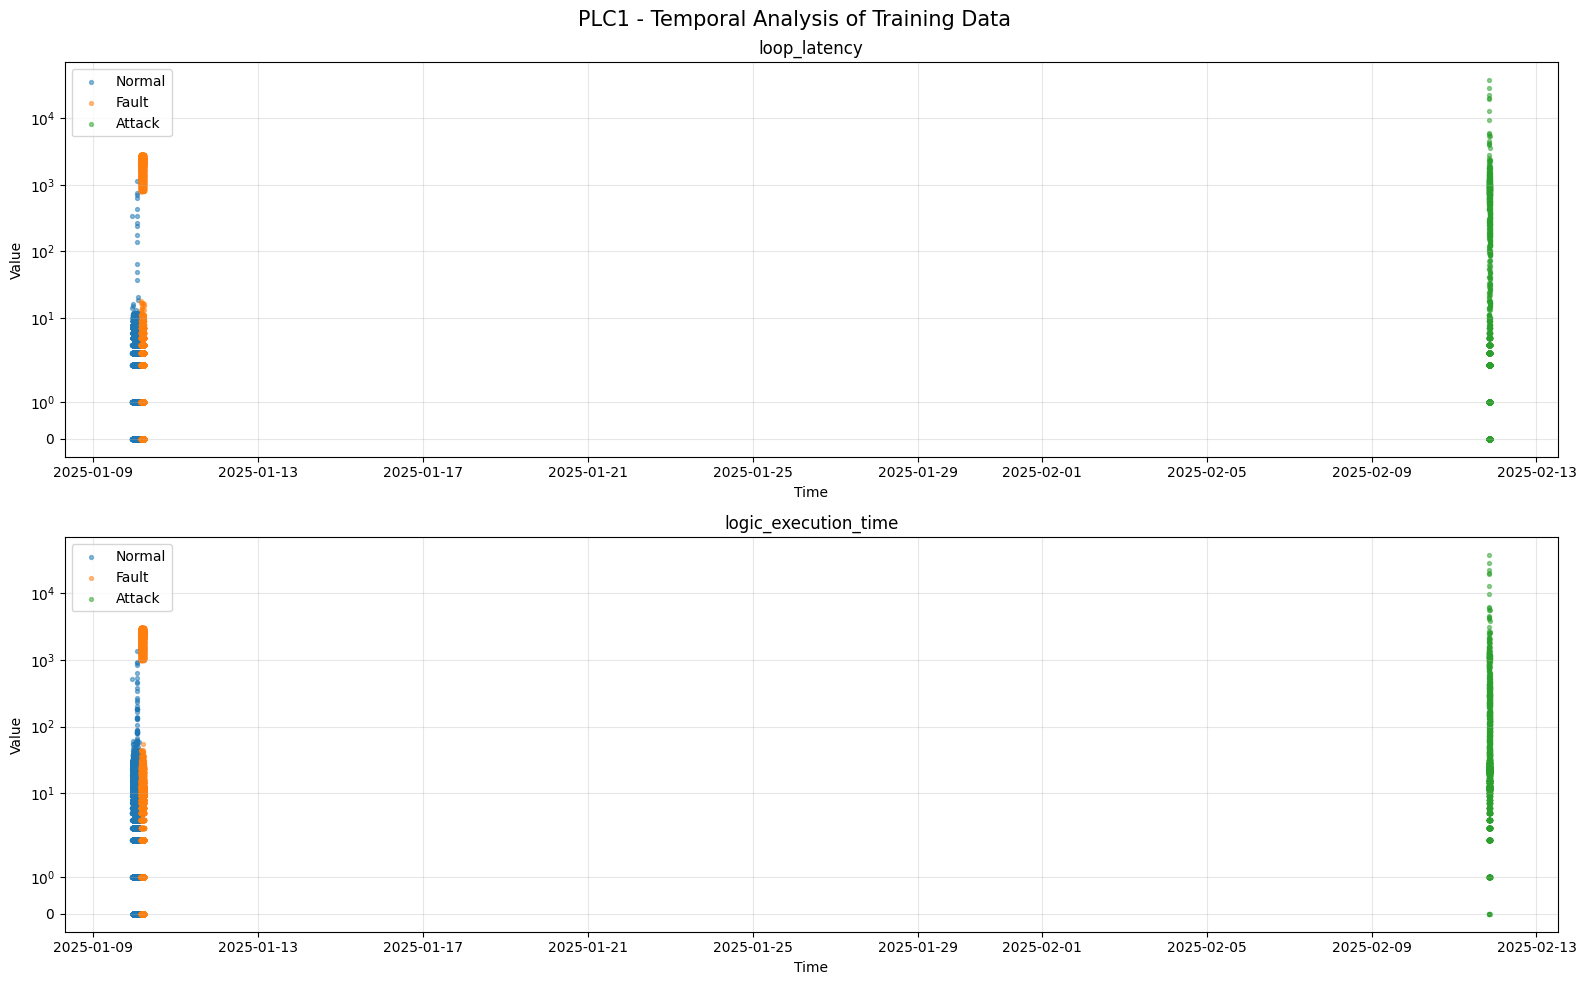

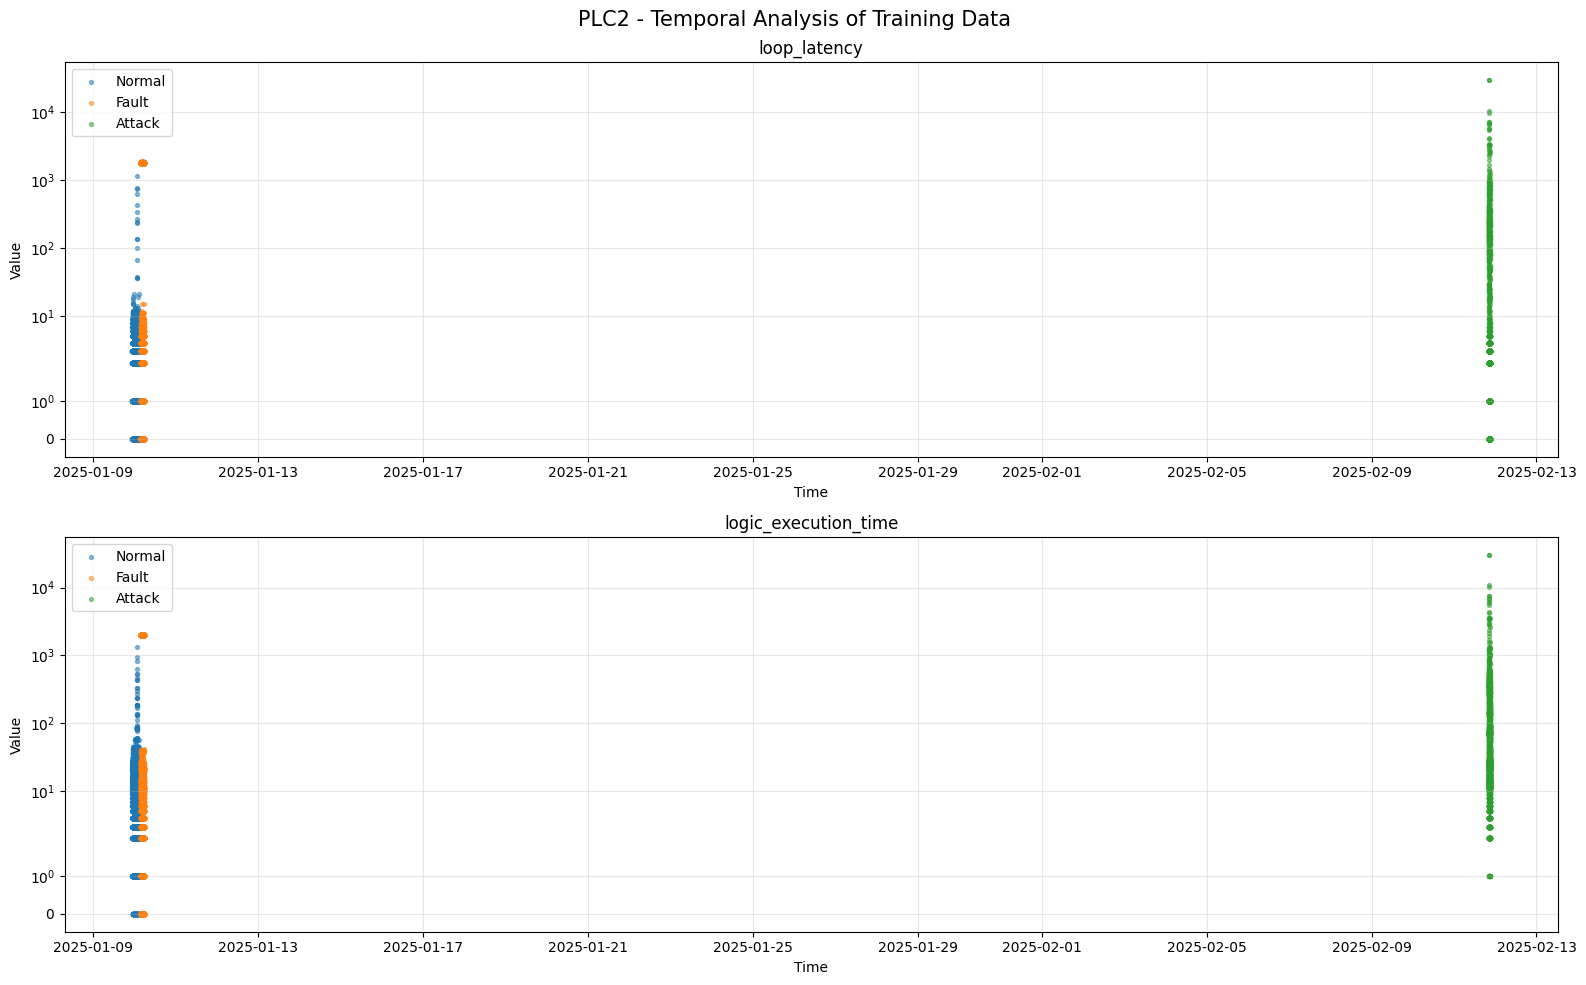

Temporal visualization completed. No data was modified.


In [42]:
import matplotlib.pyplot as plt
import pandas as pd

class_names = {
    0: "Normal",
    1: "Fault",
    2: "Attack"
}

features_to_plot = [
    "loop_latency",
    "logic_execution_time"
]

for dataset_name, (train_df, X_train) in datasets_to_check.items():

    data = train_df.reset_index(drop=True).copy()
    X = X_train.reset_index(drop=True).copy()

    data["time"] = pd.to_datetime(data["time"])

    fig, axes = plt.subplots(2, 1, figsize=(16, 10))

    fig.suptitle(
        f"{dataset_name} - Temporal Analysis of Training Data",
        fontsize=15
    )

    for ax, feature in zip(axes, features_to_plot):

        for label, class_name in class_names.items():

            mask = data["label"] == label

            ax.scatter(
                data.loc[mask, "time"],
                X.loc[mask, feature],
                label=class_name,
                alpha=0.5,
                s=8
            )

        ax.set_title(feature)
        ax.set_xlabel("Time")
        ax.set_ylabel("Value")
        ax.set_yscale("symlog")
        ax.legend()
        ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

print("Temporal visualization completed. No data was modified.")

In [43]:
for dataset_name, (train_df, X_train) in datasets_to_check.items():

    print("\n" + "=" * 65)
    print(f"TIMESTAMP RANGE BY CLASS - {dataset_name}")
    print("=" * 65)

    data = train_df.copy()
    data["time"] = pd.to_datetime(data["time"])

    for label, class_name in {
        0: "Normal",
        1: "Fault",
        2: "Attack"
    }.items():

        class_data = data[data["label"] == label]

        print(f"\n{class_name}")
        print("Rows:", len(class_data))
        print("Start:", class_data["time"].min())
        print("End:", class_data["time"].max())
        print("Unique dates:", class_data["time"].dt.date.nunique())

print("\nTimestamp inspection completed. No data was modified.")


TIMESTAMP RANGE BY CLASS - PLC1

Normal
Rows: 65296
Start: 2025-01-09 22:43:07.335284
End: 2025-01-10 02:20:51.225930
Unique dates: 2

Fault
Rows: 11696
Start: 2025-01-10 03:22:34.402877
End: 2025-01-10 05:29:31.417520
Unique dates: 1

Attack
Rows: 2800
Start: 2025-02-11 20:27:12.564045
End: 2025-02-11 20:45:14.234407
Unique dates: 1

TIMESTAMP RANGE BY CLASS - PLC2

Normal
Rows: 65293
Start: 2025-01-09 22:43:07.612774
End: 2025-01-10 02:20:51.425525
Unique dates: 2

Fault
Rows: 11701
Start: 2025-01-10 03:22:34.406896
End: 2025-01-10 05:29:19.409083
Unique dates: 1

Attack
Rows: 3872
Start: 2025-02-11 20:27:12.663132
End: 2025-02-11 20:44:52.647139
Unique dates: 1

Timestamp inspection completed. No data was modified.
